# Introduction to Machine Learning – Lab 2
## Bonus: CatBoost vs. XGBoost (and LightGBM)

### Objective
This notebook implements and tunes **CatBoost** on exactly the same features as the XGBoost models of notebooks 02–05.1 and the LightGBM models of notebook 06, and compares them:
1. **How the trees are built:** symmetric (oblivious) trees with one tree per round for all classes (CatBoost) vs. depth-wise trees with one tree per class (XGBoost), with tree plots and the shape of all trees in the ensemble.
2. **The learning process:** learning curves with early stopping, number of rounds, training time and feature importance.
3. **The results:** default models, a short manual tuning, Bayesian optimization with Optuna (`TPESampler`), and a final comparison of all three libraries on all 70 splits, each **with and without SMOTE**.

**Same setup as for XGBoost and LightGBM:** the same 2,925 houses with 72 features, the same one-hot encoding (fitted on the training part only), the same 70 splits and, for the SMOTE models, the same SMOTE step on the training part. The reference models are recomputed on the same splits:
* the default XGBoost model (notebook 02), with and without SMOTE
* the tuned XGBoost models: the best Optuna trial of notebook 05 (no SMOTE) and the manual combination of notebook 05.1 (SMOTE)
* the tuned LightGBM models of notebook 06 (best Optuna trials without and with SMOTE, loaded from their studies)

In [1]:
import io
import json
import os
import sys
import tempfile
import time
import warnings
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from lightgbm import LGBMClassifier
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler
from optuna.visualization import matplotlib as optuna_plots
from sklearn.base import clone
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from xgboost import plot_tree as xgb_plot_tree

from evaluation import evaluate, make_splits, summarize
from preprocessing import CLASS_NAMES, build_pipeline, make_preprocessor, prepare_data

sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
# The matplotlib versions of the Optuna plots are marked as experimental
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

# Same data as notebooks 02–06
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
print(f"Dataset dimensions: X = {X.shape}, y = {y.shape}")

# All 70 splits of notebooks 02–06, and the 5 folds used for tuning
splits = make_splits(y)
cv5 = [split for split in splits if split["Setup"] == "CV k=5, stratified"]
num_classes = len(CLASS_NAMES)

# XGBoost defaults (the baseline of notebook 02)
XGB_DEFAULTS = {
    "max_depth": 6, "learning_rate": 0.3, "n_estimators": 100, "min_child_weight": 1, "subsample": 1.0,
    "colsample_bytree": 1.0, "reg_lambda": 1.0, "reg_alpha": 0.0, "gamma": 0.0,
}
STORAGE = "sqlite:///optuna_ames_housing.db"
# Tuned reference models: best Optuna trials of notebooks 05 and 06, manual combination of notebook 05.1
XGB_TUNED = optuna.load_study(study_name="xgboost_macro_f1_tpe", storage=STORAGE).best_params
XGB_SMOTE_MANUAL = {
    "learning_rate": 0.05, "n_estimators": 600, "min_child_weight": 3.0,
    "subsample": 0.6, "colsample_bytree": 0.3, "reg_lambda": 5.0,
}
LGBM_TUNED = optuna.load_study(study_name="lightgbm_macro_f1_tpe", storage=STORAGE).best_params
LGBM_SMOTE_TUNED = optuna.load_study(study_name="lightgbm_smote_macro_f1_tpe", storage=STORAGE).best_params


def make_xgb(smote=False, **params):
    """XGBoost pipeline of notebooks 05 / 05.1: one-hot encoding (+ SMOTE) and XGBoost."""
    return build_pipeline(
        "onehot", min_frequency=5, smote=smote, enable_categorical=False, tree_method="hist",
        **{**XGB_DEFAULTS, **params},
    )


def make_lgbm(smote=False, **params):
    """LightGBM pipeline of notebook 06 (row sampling needs subsample_freq=1)."""
    return build_pipeline(
        "onehot", min_frequency=5, smote=smote,
        model=LGBMClassifier(random_state=42, verbose=-1, subsample_freq=1, **params),
    )


def make_cat(smote=False, **params):
    """The same encoding (+ SMOTE), with a CatBoost classifier (no files written during training)."""
    return build_pipeline(
        "onehot", min_frequency=5, smote=smote,
        model=CatBoostClassifier(random_seed=42, verbose=0, allow_writing_files=False, **params),
    )


def cv_scores(model):
    """Mean scores over the 5 stratified folds; Gap = training minus test macro-F1 (variance)."""
    scores = evaluate(model, X, y, cv5)
    return {
        "Train Macro-F1": scores["Train Macro-F1"].mean(),
        "Test Macro-F1": scores["Test Macro-F1"].mean(),
        "Test Macro-F1 Std": scores["Test Macro-F1"].std(),
        "Test Accuracy": scores["Test Accuracy"].mean(),
        "Gap": scores["Train Macro-F1"].mean() - scores["Test Macro-F1"].mean(),
    }


def run_models(models):
    """Fit and score every model on all 70 splits; also return the mean time per fit (incl. prediction)."""
    results, seconds = [], {}
    for name, model in models.items():
        start = time.perf_counter()
        results.append(evaluate(model, X, y, splits).assign(Variant=name))
        seconds[name] = (time.perf_counter() - start) / len(splits)
    return pd.concat(results, ignore_index=True), pd.Series(seconds, name="Seconds per fit")


def paired(results, pairs):
    """Macro-F1 of model a minus macro-F1 of model b on the same split, for every pair (a, b)."""
    wide = results.pivot_table(index=["Setup", "Split"], columns="Variant", values="Test Macro-F1")
    experiment = wide.index.get_level_values("Setup").str.split().str[0]
    table = {}
    for a, b in pairs:
        diff = wide[a] - wide[b]
        groups = [*diff.groupby(experiment, sort=False), ("All 70 splits", diff)]
        table[f"{a} − {b}"] = {
            (name, stat): value
            for name, group in groups
            for stat, value in [("Mean Difference", group.mean()), ("Std", group.std()),
                                ("Better", (group > 0).sum()), ("Worse", (group < 0).sum())]
        }
    return pd.DataFrame(table).T.round(4)


def gap_table(results):
    """Training vs. test macro-F1, averaged over all 70 splits."""
    gap = results.groupby("Variant", sort=False)[["Train Macro-F1", "Test Macro-F1"]].mean()
    gap["Gap"] = gap["Train Macro-F1"] - gap["Test Macro-F1"]
    return gap.round(4)

Dataset dimensions: X = (2925, 72), y = (2925,)


### 1. How the trees are built
CatBoost is also gradient boosting with histograms (at most 254 borders per feature) and the same gain formula with an L2 penalty (`l2_leaf_reg`, default 3). Its trees, however, are built differently from XGBoost's:
* **Symmetric (oblivious) trees:** all nodes of one level use the **same split** (the same feature and threshold). A tree of depth $d$ is therefore just a list of $d$ yes/no tests, and the leaf of a house is the $d$-bit code of its answers. Every tree is perfectly balanced with exactly $2^d$ leaves, and it has only $d$ split conditions instead of up to $2^d - 1$ in an XGBoost tree of the same depth. The split of a level is chosen to reduce the loss summed over all nodes of the level, so a single split must be useful for all parts of the tree at once. This is a strong built-in regularization, and it makes prediction very fast.
* **One tree per round for all classes:** for six classes, XGBoost (and LightGBM) build six trees per round, one per class. CatBoost builds **one** tree per round whose leaves hold a vector of six values, one per class. Every split must therefore help all classes together.
* **Randomness in every tree:** by default, every tree uses a *Bayesian bootstrap* (each training house gets a random weight, `bagging_temperature` = 1), and a random noise term is added to the split scores (`random_strength` = 1), so that the trees differ more from each other.
* **Ordered boosting and target statistics:** CatBoost's best-known techniques fight the "prediction shift" of gradient boosting and turn categorical features into numbers with ordered target statistics. Here the nominal features are already one-hot encoded (the same features as for XGBoost), so no target statistics are used, and CatBoost chooses `Plain` boosting (printed below).

**Plots:** as in notebook 06, both libraries get the **same leaf budget of 8 leaves per tree**: XGBoost with `max_depth=3`, CatBoost with `depth=3`. Both use `learning_rate=0.1` and early stopping on the same 20% stratified validation split as in notebook 03 (boosting stops when the validation log-loss has not improved for 20 rounds). For XGBoost, the class-0 tree (`< 100k`) is shown; for CatBoost, the single tree of the round, with six values per leaf.

XGBoost  (max_depth=3): best round 282, validation log-loss 0.5641, 1.7 s for 303 rounds
CatBoost (depth=3):     best round 445, validation log-loss 0.5521, 1.1 s for 466 rounds

CatBoost settings (library defaults unless set above)


,Value
grow_policy,SymmetricTree
depth,3
loss_function,MultiClass
boosting_type,Plain
bootstrap_type,Bayesian
bagging_temperature,1
random_strength,1
l2_leaf_reg,3
border_count,254
leaf_estimation_method,Newton


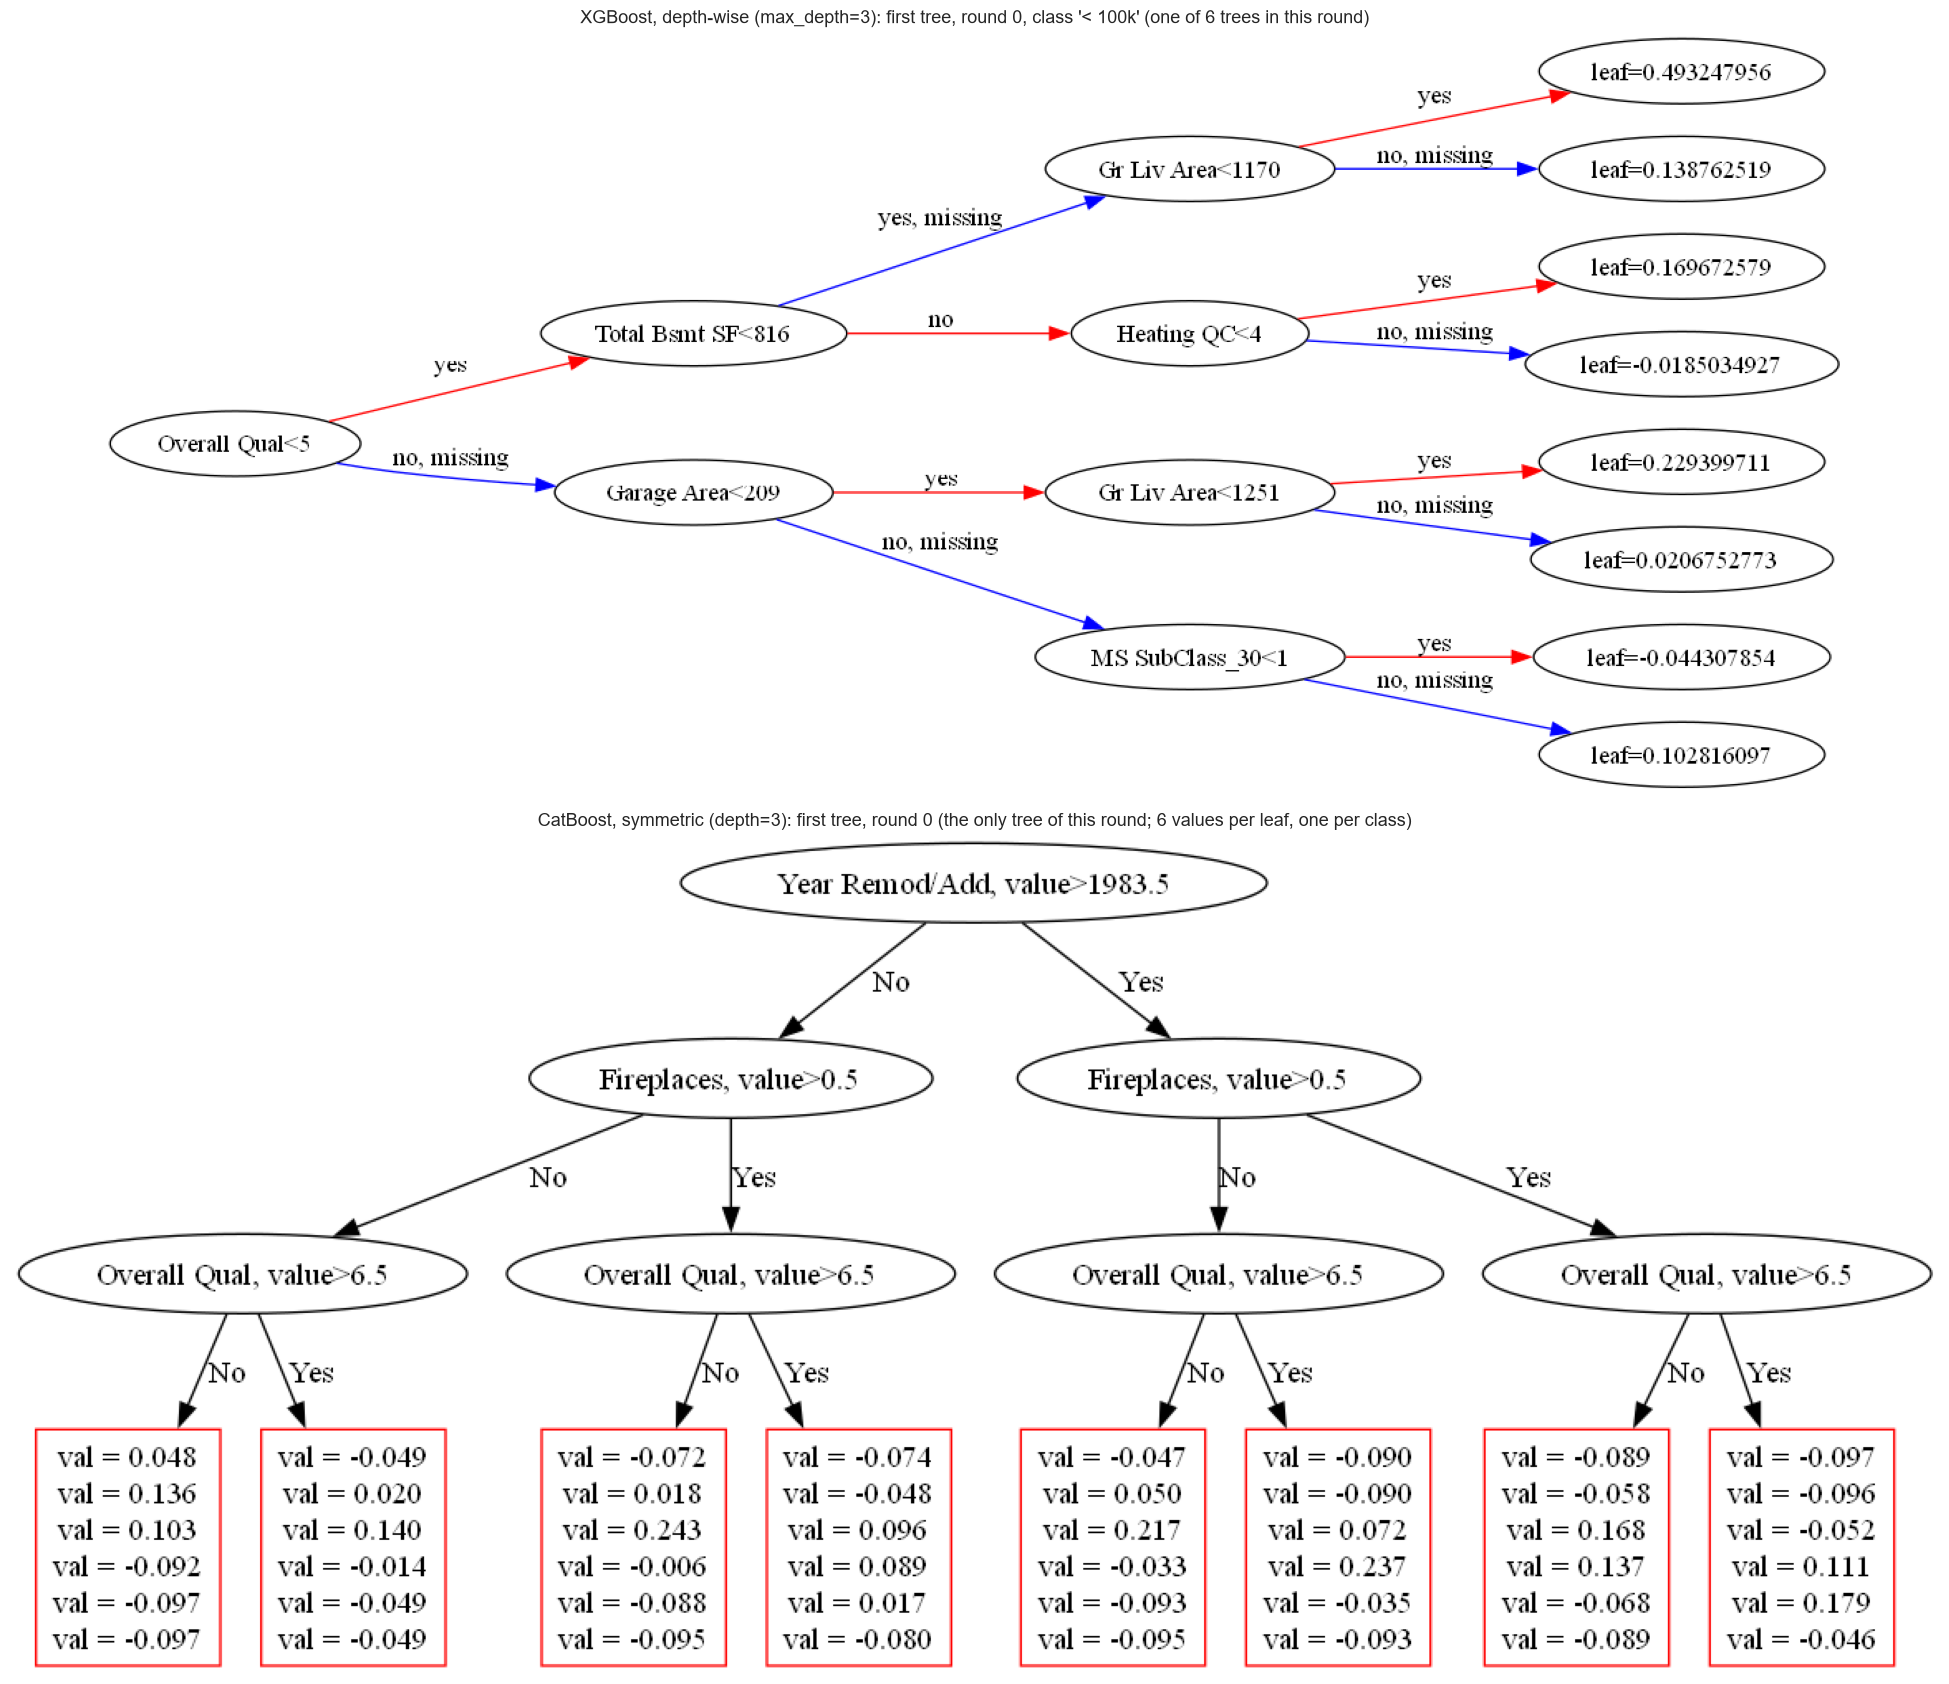

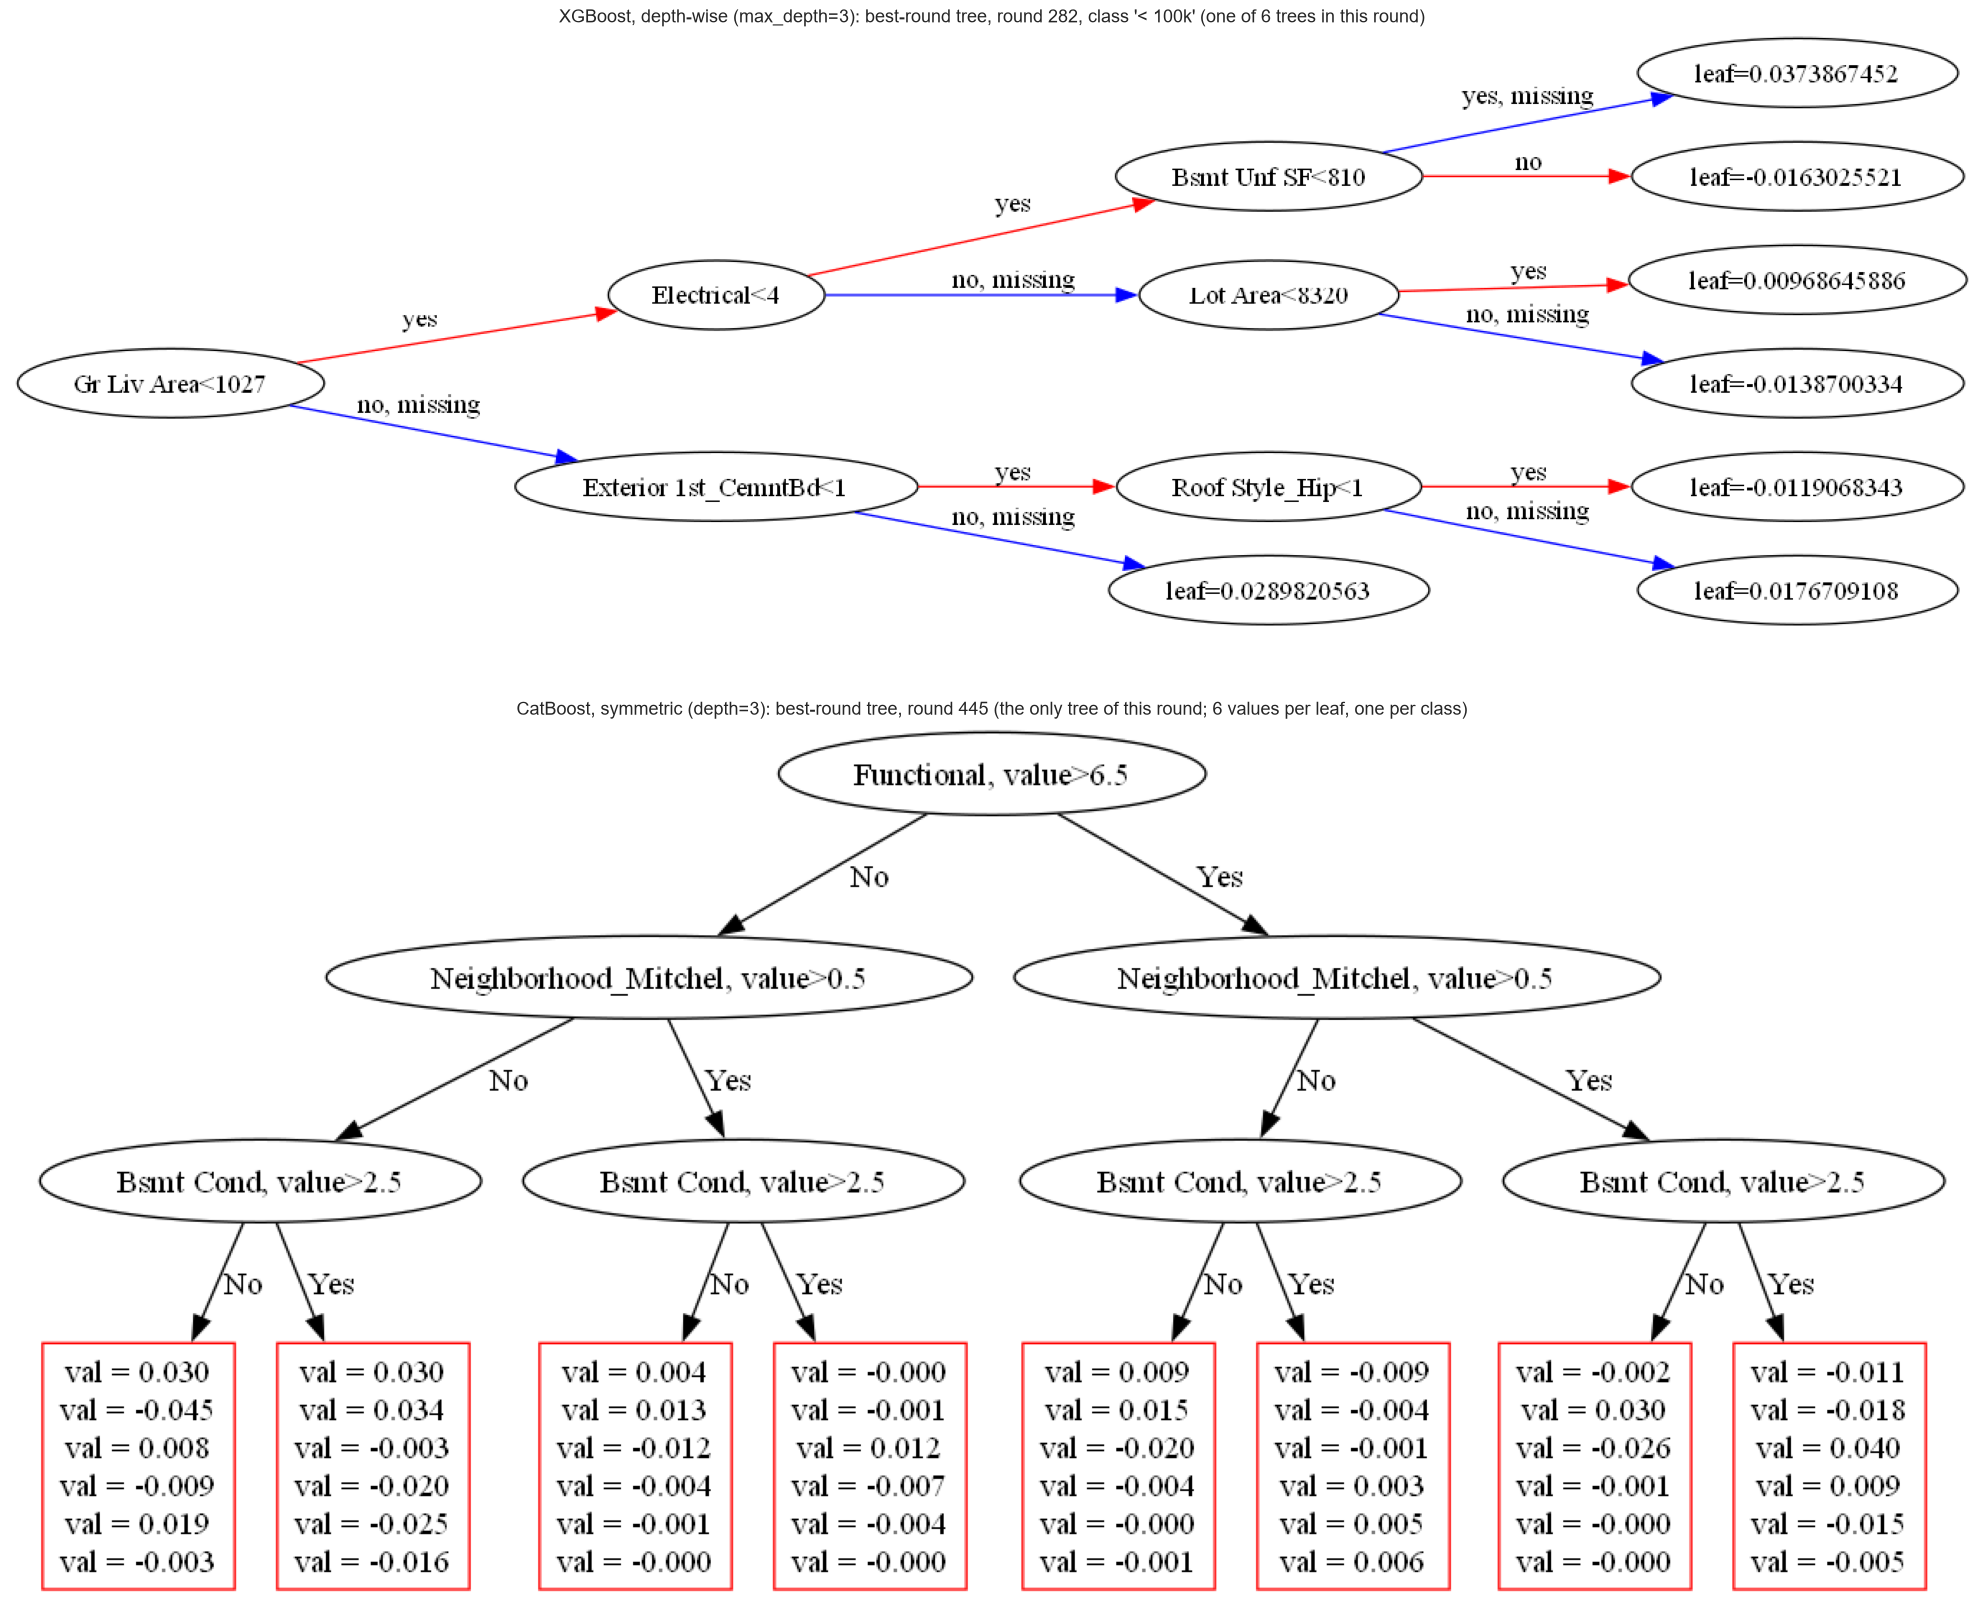

In [2]:
# 80/20 stratified split: the 20% validation houses decide when boosting stops (as in notebook 03)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
prep = make_preprocessor("onehot", min_frequency=5)
X_train_enc = prep.fit_transform(X_train, y_train)
X_val_enc = prep.transform(X_val)

# Same leaf budget: XGBoost depth-wise with max_depth=3, CatBoost symmetric trees with depth=3
xgb_small = XGBClassifier(
    n_estimators=1000, learning_rate=0.1, max_depth=3, eval_metric="mlogloss",
    early_stopping_rounds=20, tree_method="hist", random_state=42,
)
start = time.perf_counter()
xgb_small.fit(X_train_enc, y_train, eval_set=[(X_train_enc, y_train), (X_val_enc, y_val)], verbose=False)
xgb_seconds = time.perf_counter() - start

# CatBoost keeps only the trees up to the best round (use_best_model), the curves cover all rounds
cat_small = CatBoostClassifier(iterations=3000, depth=3, learning_rate=0.1, random_seed=42, verbose=0,
                               allow_writing_files=False)
start = time.perf_counter()
cat_small.fit(X_train_enc, y_train, eval_set=(X_val_enc, y_val), early_stopping_rounds=20)
cat_seconds = time.perf_counter() - start

best_xgb, best_cat = xgb_small.best_iteration, cat_small.best_iteration_
print(f"XGBoost  (max_depth=3): best round {best_xgb}, validation log-loss {xgb_small.best_score:.4f}, "
      f"{xgb_seconds:.1f} s for {best_xgb + 21} rounds")
print(f"CatBoost (depth=3):     best round {best_cat}, validation log-loss "
      f"{cat_small.best_score_['validation']['MultiClass']:.4f}, {cat_seconds:.1f} s for {best_cat + 21} rounds")

settings = cat_small.get_all_params()
print("\nCatBoost settings (library defaults unless set above)")
display(pd.Series({key: settings[key] for key in [
    "grow_policy", "depth", "loss_function", "boosting_type", "bootstrap_type", "bagging_temperature",
    "random_strength", "l2_leaf_reg", "border_count", "leaf_estimation_method",
]}, name="Value").to_frame())


def show_trees(round_xgb, round_cat, label):
    """Class-0 XGBoost tree (index = round × 6) and the single CatBoost tree of the given round."""
    fig, axes = plt.subplots(2, 1, figsize=(20, 17), gridspec_kw={"height_ratios": [1, 1.1]})
    xgb_plot_tree(xgb_small, tree_idx=round_xgb * num_classes, rankdir="LR", ax=axes[0])
    axes[0].set_title(f"XGBoost, depth-wise (max_depth=3): {label}, round {round_xgb}, class '{CLASS_NAMES[0]}' "
                      f"(one of 6 trees in this round)", fontsize=13)
    graph = cat_small.plot_tree(tree_idx=round_cat, pool=Pool(X_train_enc, y_train))
    axes[1].imshow(plt.imread(io.BytesIO(graph.pipe(format="png")), format="png"))
    axes[1].axis("off")
    axes[1].set_title(f"CatBoost, symmetric (depth=3): {label}, round {round_cat} "
                      f"(the only tree of this round; 6 values per leaf, one per class)", fontsize=13)
    plt.tight_layout()
    plt.show()


show_trees(0, 0, "first tree")
show_trees(best_xgb, best_cat, "best-round tree")

#### Interpretation of the trees
* **One split per level:** the CatBoost tree tests the same condition on all nodes of a level. The first tree asks `Year Remod/Add > 1983.5`, then `Fireplaces > 0.5`, then `Overall Qual > 6.5`, and every house falls into one of the $2^3 = 8$ combinations of answers. The XGBoost tree uses 7 different conditions for its 7 split nodes.
* **One tree for all classes:** every CatBoost leaf holds six values, one per price class (in the first tree between about −0.10 and +0.24). A house with a recent remodeling, a fireplace and a high quality gets a lower score for the cheap classes and a higher one for the expensive classes, all from the same tree. XGBoost's first tree only serves the class `< 100k`, so it starts with the feature that isolates the cheapest houses best (`Overall Qual < 5`). CatBoost has to choose splits that help all six classes at once, which is why it starts with more general features (age of the last remodeling, fireplace, high quality). The random noise on the split scores (`random_strength`) also lets it pick a split that is not the single best one.
* **Best-round trees:** both trees make only small corrections. CatBoost's leaves in round 445 are at most 0.045 in absolute value, its splits use `Functional`, `Neighborhood_Mitchel` and `Bsmt Cond`. XGBoost's tree (round 282) uses 6 different split conditions.
* **Learning in rounds:** CatBoost reaches its best validation log-loss after 445 rounds, but it needs only one tree per round. In total it fits 446 trees instead of XGBoost's 1,698 (283 rounds × 6), and the training took 1.1 s instead of 1.7 s.

#### 1.1 Shape of all trees in the ensemble
For the 8-leaf pair above (trees up to the best round) and for the two default models (XGBoost `max_depth=6` with 100 rounds, CatBoost `depth=6` with 1,000 rounds and its automatic learning rate), fitted on the same 80% training part: trees per round, leaves, split conditions and different features per tree, and leaf values per round (the number of fitted parameters).

CatBoost default: 1000 rounds in 7.1 s, learning rate 0.0826 (set automatically)


,Rounds,Trees per round,Trees,Mean leaves per tree,Mean split conditions per tree,Mean different features per tree,Leaf values per round
"XGBoost, max_depth=3",283.0,6.0,1698.0,6.84,5.84,5.48,41.05
"CatBoost, depth=3",446.0,1.0,446.0,8.00,3.00,2.98,48.00
XGBoost default (max_depth=6),100.0,6.0,600.0,18.82,17.82,13.30,112.92
CatBoost default (depth=6),1000.0,1.0,1000.0,63.91,6.00,5.89,383.47


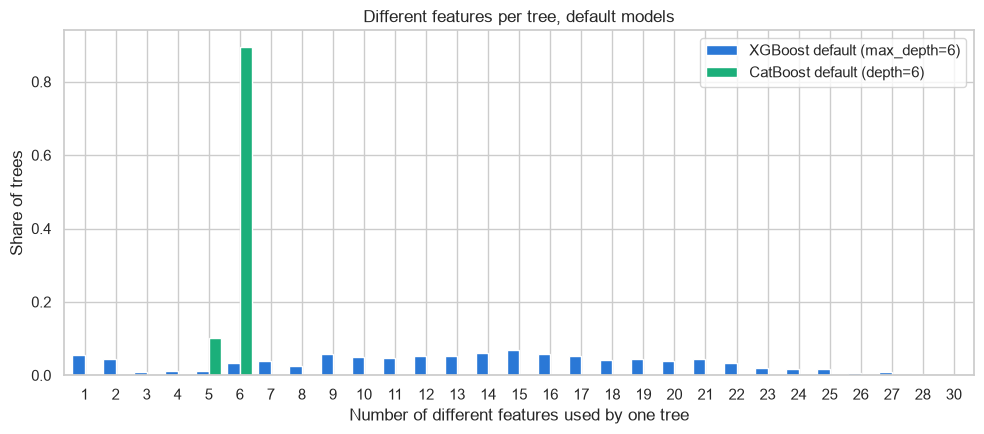

In [3]:
def xgb_tree_shapes(model, n_rounds):
    """Leaves, split conditions and different features of the XGBoost trees of the first n_rounds rounds."""
    df = model.get_booster().trees_to_dataframe()
    df = df[df["Tree"] < n_rounds * num_classes]
    splits_only = df[df["Feature"] != "Leaf"]
    return pd.DataFrame({
        "Leaves": df[df["Feature"] == "Leaf"].groupby("Tree").size(),
        "Split conditions": splits_only.groupby("Tree").size(),
        "Different features": splits_only.groupby("Tree")["Feature"].nunique(),
    }).fillna(0)


def cat_tree_shapes(model):
    """The same for all CatBoost trees, read from the model exported as JSON."""
    with tempfile.TemporaryDirectory() as folder:
        path = os.path.join(folder, "model.json")
        model.save_model(path, format="json")
        with open(path) as file:
            trees = json.load(file)["oblivious_trees"]
    return pd.DataFrame([
        {
            "Leaves": len(tree["leaf_values"]) // num_classes,
            "Split conditions": len(tree["splits"]),
            "Different features": len({split["float_feature_index"] for split in tree["splits"]}),
        }
        for tree in trees
    ]), trees


# Default models on the same training part
xgb_default = XGBClassifier(**XGB_DEFAULTS, tree_method="hist", random_state=42).fit(X_train_enc, y_train)
start = time.perf_counter()
cat_default = CatBoostClassifier(random_seed=42, verbose=0, allow_writing_files=False).fit(X_train_enc, y_train)
print(f"CatBoost default: {cat_default.tree_count_} rounds in {time.perf_counter() - start:.1f} s, "
      f"learning rate {cat_default.get_all_params()['learning_rate']:.4f} (set automatically)")

cat_small_shapes, _ = cat_tree_shapes(cat_small)
cat_default_shapes, cat_default_trees = cat_tree_shapes(cat_default)
shapes = {
    "XGBoost, max_depth=3": (xgb_tree_shapes(xgb_small, best_xgb + 1), best_xgb + 1, num_classes),
    "CatBoost, depth=3": (cat_small_shapes, best_cat + 1, 1),
    "XGBoost default (max_depth=6)": (xgb_tree_shapes(xgb_default, 100), 100, num_classes),
    "CatBoost default (depth=6)": (cat_default_shapes, cat_default.tree_count_, 1),
}
display(pd.DataFrame({
    name: {
        "Rounds": rounds, "Trees per round": per_round, "Trees": len(df),
        "Mean leaves per tree": df["Leaves"].mean(),
        "Mean split conditions per tree": df["Split conditions"].mean(),
        "Mean different features per tree": df["Different features"].mean(),
        "Leaf values per round": df["Leaves"].mean() * num_classes,
    }
    for name, (df, rounds, per_round) in shapes.items()
}).T.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
features = pd.DataFrame({
    name: shapes[name][0]["Different features"].value_counts(normalize=True)
    for name in ["XGBoost default (max_depth=6)", "CatBoost default (depth=6)"]
}).fillna(0).sort_index()
features.plot.bar(ax=ax, color=["#2a78d6", "#1baf7a"], width=0.8)
ax.set_title("Different features per tree, default models", fontsize=12)
ax.set_xlabel("Number of different features used by one tree")
ax.set_ylabel("Share of trees")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

#### Interpretation of the tree shapes
* **Same leaf budget (depth 3):**
  * A CatBoost tree has 8 leaves but only 3 split conditions, on 2.98 different features on average.
  * An XGBoost tree has 6.84 leaves, 5.84 split conditions and 5.48 different features. XGBoost needs six such trees per round, CatBoost one, with 48 leaf values instead of 41.05.
* **Default settings:**
  * CatBoost's trees are full depth-6 trees with 63.91 leaves on average (a few trees stop earlier), but still only 6 split conditions on 5.89 different features. About 90% of them use 6 different features (plot).
  * XGBoost's default trees have 18.82 leaves, 17.82 split conditions and 13.30 different features, spread widely between 1 and 30 features per tree.
  * CatBoost fits 1,000 such trees with 383.47 leaf values each (64 leaves × 6 classes), XGBoost 100 rounds of 6 trees with 112.92 leaf values per round. CatBoost's default model therefore has many more parameters, but each tree can only describe a very regular pattern ($d$ yes/no questions).
* **Why this regularizes:** a symmetric tree cannot follow a small group of houses down a special path, because every split is applied to all houses of the level. Overly specific leaves are therefore much less likely than in a depth-wise or leaf-wise tree.

### 2. The learning process
* **Learning curves** of the 8-leaf pair of Section 1: training and validation log-loss per round, with the best round.
* **Feature importance** of the two default models. CatBoost has no "total gain"; its default importance, *PredictionValuesChange*, measures how much the predictions change on average when a feature's value changes. It is compared with XGBoost's total gain. The split counts are compared directly; for CatBoost, a split condition counts once per tree, although it is applied on every node of its level.

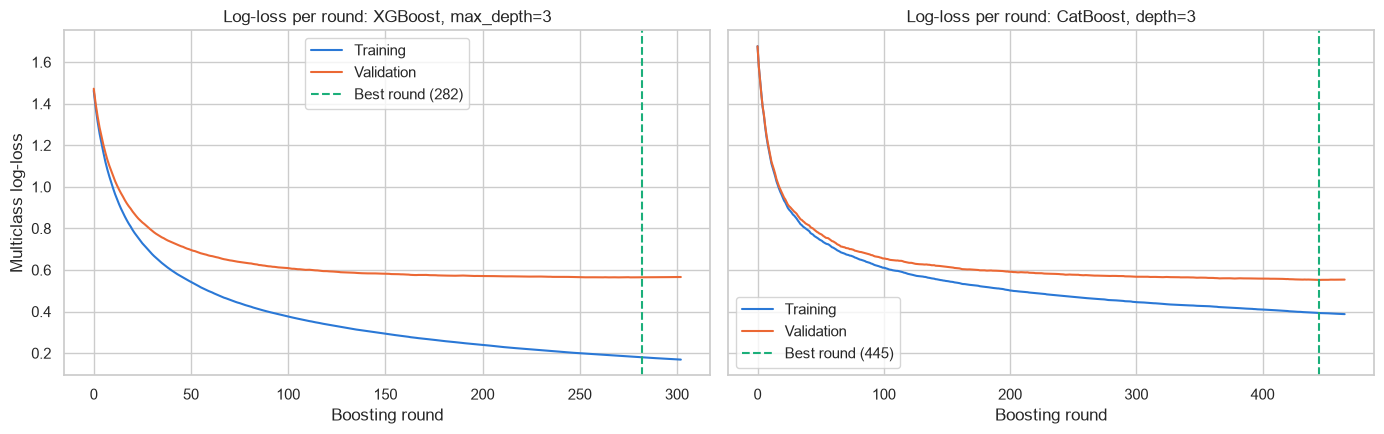

Log-loss at the best round


,Best round,Training,Validation,Gap
"XGBoost, max_depth=3",282.0,0.1797,0.5641,0.3844
"CatBoost, depth=3",445.0,0.3929,0.5521,0.1592


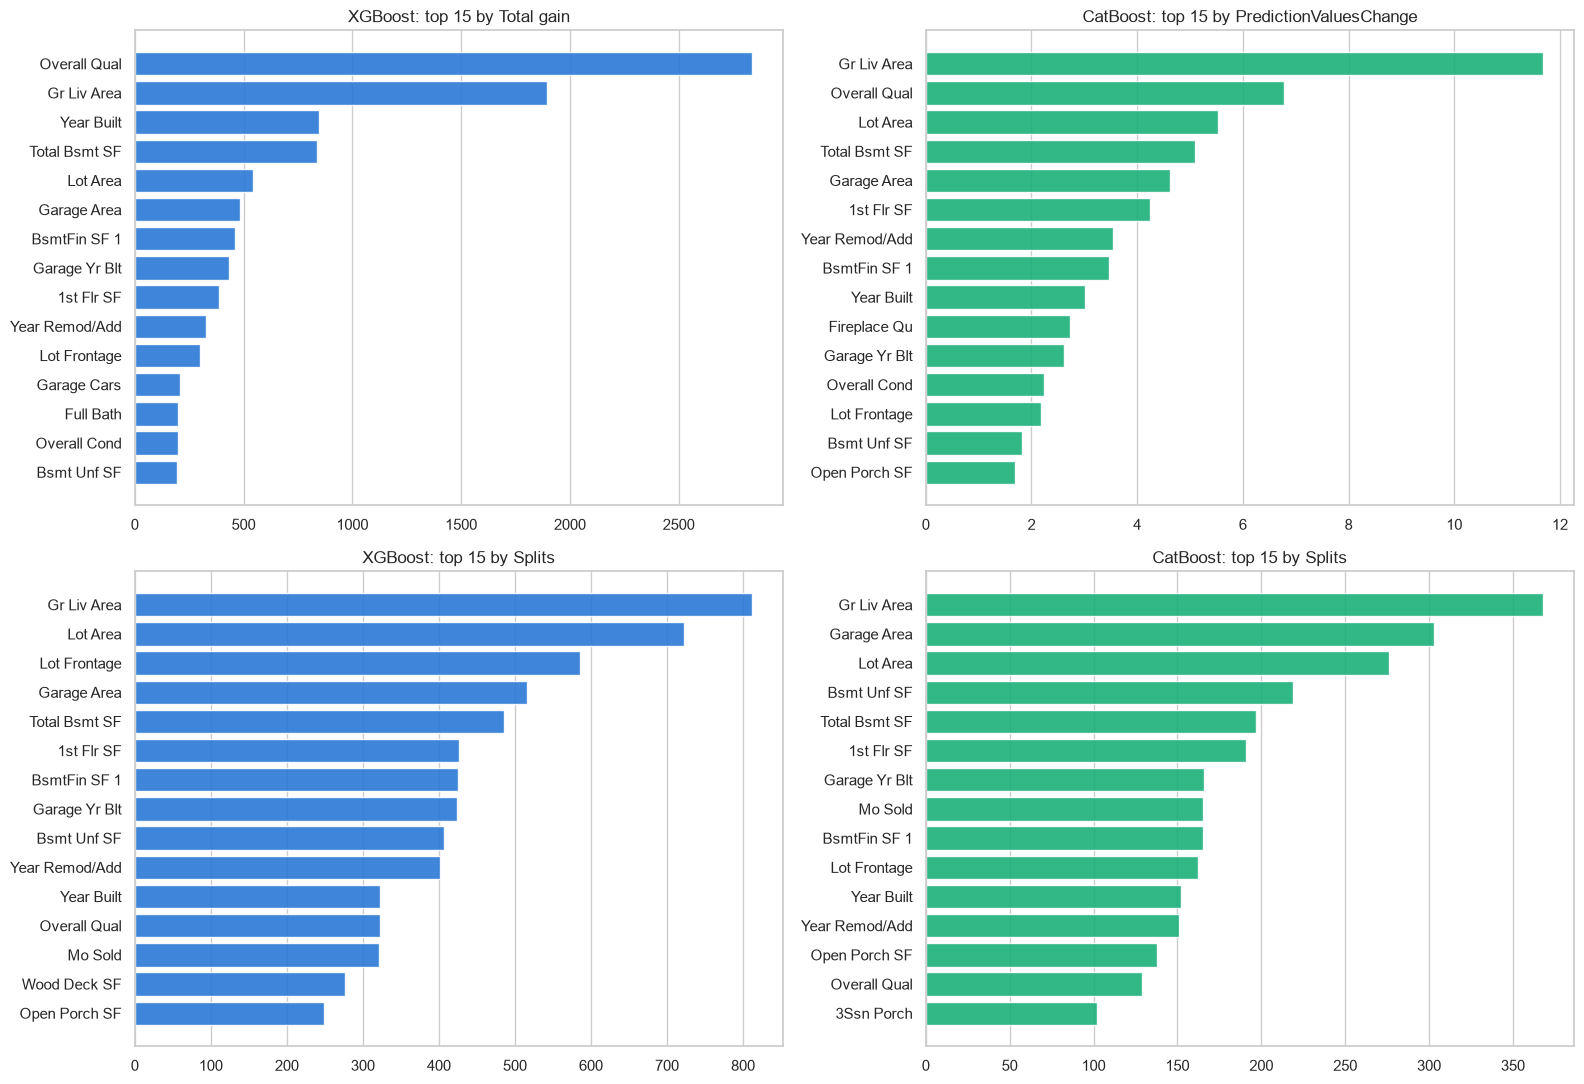

Rank correlation (Spearman) between the libraries, over all encoded features


,Spearman r
XGBoost total gain vs. CatBoost PredictionValuesChange,0.903
Split counts,0.678


Top 10 by CatBoost PredictionValuesChange with the ranks in both libraries


XGBoost                      CatBoost       
               Total gain Splits PredictionValuesChange Splits
Gr Liv Area             2      1                      1      1
Overall Qual            1     11                      2     14
Lot Area                5      2                      3      3
Total Bsmt SF           4      5                      4      5
Garage Area             6      4                      5      2
1st Flr SF              9      6                      6      6
Year Remod/Add         10     10                      7     12
BsmtFin SF 1            7      7                      8      8
Year Built              3     11                      9     11
Fireplace Qu           19     23                     10     23

Features used in at least one split: XGBoost 155, CatBoost 186 of 200


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
cat_curves = cat_small.get_evals_result()
curves = {
    "XGBoost, max_depth=3": (xgb_small.evals_result()["validation_0"]["mlogloss"],
                             xgb_small.evals_result()["validation_1"]["mlogloss"], best_xgb),
    "CatBoost, depth=3": (cat_curves["learn"]["MultiClass"], cat_curves["validation"]["MultiClass"], best_cat),
}
for ax, (name, (train_curve, val_curve, best)) in zip(axes, curves.items()):
    ax.plot(train_curve, label="Training", color="#2a78d6")
    ax.plot(val_curve, label="Validation", color="#eb6834")
    ax.axvline(best, color="#1baf7a", linestyle="--", label=f"Best round ({best})")
    ax.set_title(f"Log-loss per round: {name}", fontsize=12)
    ax.set_xlabel("Boosting round")
    ax.legend()
axes[0].set_ylabel("Multiclass log-loss")
plt.tight_layout()
plt.show()

print("Log-loss at the best round")
display(pd.DataFrame({
    name: {"Best round": best, "Training": train_curve[best], "Validation": val_curve[best],
           "Gap": val_curve[best] - train_curve[best]}
    for name, (train_curve, val_curve, best) in curves.items()
}).T.round(4))

# Split counts of the CatBoost default model: one per split condition and tree
cat_split_counts = pd.Series(
    [cat_default.feature_names_[split["float_feature_index"]] for tree in cat_default_trees for split in tree["splits"]]
).value_counts()
importance = pd.DataFrame({
    ("XGBoost", "Total gain"): pd.Series(xgb_default.get_booster().get_score(importance_type="total_gain")),
    ("XGBoost", "Splits"): pd.Series(xgb_default.get_booster().get_score(importance_type="weight")),
    ("CatBoost", "PredictionValuesChange"): pd.Series(cat_default.get_feature_importance(type="PredictionValuesChange"),
                                                      index=cat_default.feature_names_),
    ("CatBoost", "Splits"): cat_split_counts,
}).fillna(0)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for row, (xgb_measure, cat_measure) in enumerate([("Total gain", "PredictionValuesChange"), ("Splits", "Splits")]):
    for col, (library, measure, color) in enumerate([("XGBoost", xgb_measure, "#2a78d6"),
                                                     ("CatBoost", cat_measure, "#1baf7a")]):
        top = importance[(library, measure)].sort_values().tail(15)
        axes[row, col].barh(top.index, top.values, color=color, alpha=0.9)
        axes[row, col].set_title(f"{library}: top 15 by {measure}", fontsize=12)
        axes[row, col].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("Rank correlation (Spearman) between the libraries, over all encoded features")
display(pd.Series({
    "XGBoost total gain vs. CatBoost PredictionValuesChange":
        importance[("XGBoost", "Total gain")].corr(importance[("CatBoost", "PredictionValuesChange")], method="spearman"),
    "Split counts": importance[("XGBoost", "Splits")].corr(importance[("CatBoost", "Splits")], method="spearman"),
}, name="Spearman r").round(3).to_frame())
ranks = importance.rank(ascending=False, method="min").astype(int)
print("Top 10 by CatBoost PredictionValuesChange with the ranks in both libraries")
display(ranks.sort_values(("CatBoost", "PredictionValuesChange")).head(10))
print(f"Features used in at least one split: XGBoost {(importance[('XGBoost', 'Splits')] > 0).sum()}, "
      f"CatBoost {(importance[('CatBoost', 'Splits')] > 0).sum()} of {X_train_enc.shape[1]}")

#### Interpretation of the learning process
* **Smallest gap:** with the same leaf budget, CatBoost has by far the smallest distance between training and validation log-loss at the best round (0.1592 vs. 0.3844 for XGBoost). Its training log-loss stays much higher (0.3929 vs. 0.1797), yet its validation log-loss is the lowest of the three libraries (0.5521; XGBoost 0.5641, LightGBM 0.5698 in notebook 06). The symmetric trees, the Bayesian bootstrap and the noise on the split scores keep CatBoost from fitting the training houses as closely, and this generalizes better.
* **Feature importance:** the most important features are the same as for XGBoost. The rank correlation between XGBoost's total gain and CatBoost's PredictionValuesChange is 0.903. `Gr Liv Area` is first in CatBoost (second in XGBoost), followed by `Overall Qual`, `Lot Area`, `Total Bsmt SF` and `Garage Area`. One exception is `Fireplace Qu`, rank 10 in CatBoost and 19 in XGBoost, a related feature (`Fireplaces`) is used in the first CatBoost tree.
* **Split counts differ more** (rank correlation 0.678), and CatBoost uses 186 of the 200 encoded features vs. 155 for XGBoost. Its splits have to work for a whole level and for all classes at once, and the random noise on the split scores spreads them over more features. `Overall Qual`, for example, is chosen rarely (split rank 14) but has a large effect on the predictions.

### 3. Default models on all 70 splits
CatBoost and XGBoost with their default hyperparameters, each with and without SMOTE, fitted and scored on the same 70 splits. CatBoost's defaults are much larger (1,000 rounds of depth-6 trees with an automatic learning rate, vs. 100 rounds for XGBoost), which shows in the time per fit.

In [5]:
DEFAULT_MODELS = {
    "XGBoost defaults": make_xgb(),
    "CatBoost defaults": make_cat(),
    "XGBoost defaults + SMOTE": make_xgb(smote=True),
    "CatBoost defaults + SMOTE": make_cat(smote=True),
}
default_results, default_seconds = run_models(DEFAULT_MODELS)

print("Test macro-F1, mean ± std over the splits of each setup")
display(summarize(default_results, "Test Macro-F1"))
print("Training vs. test macro-F1 over all 70 splits, and time per fit")
display(gap_table(default_results).join(default_seconds.round(2)))
print("Paired differences in macro-F1 on the same split")
display(paired(default_results, [
    ("CatBoost defaults", "XGBoost defaults"),
    ("CatBoost defaults + SMOTE", "XGBoost defaults + SMOTE"),
    ("CatBoost defaults + SMOTE", "CatBoost defaults"),
]))

Test macro-F1, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
XGBoost defaults,0.7486 ± 0.0238,0.7596 ± 0.0342,0.7357 ± 0.0172,0.7546 ± 0.0245,0.7421 ± 0.0286,0.7494 ± 0.0236,0.7574 ± 0.0252,0.7546 ± 0.0432
CatBoost defaults,0.7689 ± 0.0250,0.7757 ± 0.0583,0.7722 ± 0.0193,0.7696 ± 0.0280,0.7626 ± 0.0225,0.7561 ± 0.0097,0.7635 ± 0.0214,0.7706 ± 0.0471
XGBoost defaults + SMOTE,0.7688 ± 0.0224,0.7800 ± 0.0239,0.7579 ± 0.0217,0.7671 ± 0.0189,0.7445 ± 0.0235,0.7479 ± 0.0204,0.7535 ± 0.0351,0.7634 ± 0.0342
CatBoost defaults + SMOTE,0.7808 ± 0.0272,0.7950 ± 0.0246,0.7826 ± 0.0152,0.7820 ± 0.0176,0.7698 ± 0.0348,0.7628 ± 0.0337,0.7636 ± 0.0383,0.7758 ± 0.0432


Training vs. test macro-F1 over all 70 splits, and time per fit


,Train Macro-F1,Test Macro-F1,Gap,Seconds per fit
Variant,,,,
XGBoost defaults,1.0000,0.7509,0.2491,1.12
CatBoost defaults,0.9977,0.7686,0.2291,7.47
XGBoost defaults + SMOTE,1.0000,0.7624,0.2376,1.47
CatBoost defaults + SMOTE,0.9914,0.7780,0.2134,8.90


Paired differences in macro-F1 on the same split


CV          \
                                                   Mean Difference     Std   
CatBoost defaults − XGBoost defaults                        0.0119  0.0241   
CatBoost defaults + SMOTE − XGBoost defaults + ...          0.0142  0.0232   
CatBoost defaults + SMOTE − CatBoost defaults               0.0040  0.0269   

                                                                 \
                                                   Better Worse   
CatBoost defaults − XGBoost defaults                 20.0  10.0   
CatBoost defaults + SMOTE − XGBoost defaults + ...   23.0   7.0   
CatBoost defaults + SMOTE − CatBoost defaults        15.0  15.0   

                                                           Holdout          \
                                                   Mean Difference     Std   
CatBoost defaults − XGBoost defaults                        0.0220  0.0277   
CatBoost defaults + SMOTE − XGBoost defaults + ...          0.0167  0.0238   
CatBoost defaults + SMOTE − CatBoost defaults               0.0135  0.0307   

                                                                 \
                                                   Better Worse   
CatBoost defaults − XGBoost defaults                 30.0  10.0   
CatBoost defaults + SMOTE − XGBoost defaults + ...   32.0   8.0   
CatBoost defaults + SMOTE − CatBoost defaults        26.0  14.0   

                                                     All 70 splits          \
                                                   Mean Difference     Std   
CatBoost defaults − XGBoost defaults                        0.0177  0.0265   
CatBoost defaults + SMOTE − XGBoost defaults + ...          0.0156  0.0234   
CatBoost defaults + SMOTE − CatBoost defaults               0.0094  0.0293   

                                                                 
                                                   Better Worse  
CatBoost defaults − XGBoost defaults                 50.0  20.0  
CatBoost defaults + SMOTE − XGBoost defaults + ...   55.0  15.0  
CatBoost defaults + SMOTE − CatBoost defaults        41.0  29.0

#### Interpretation of the default models
* **CatBoost's defaults are already very strong:** a mean test macro-F1 of 0.7686 without and 0.7780 with SMOTE. That is more than XGBoost's defaults (0.7509 / 0.7624), and more than the *tuned* XGBoost and LightGBM models without SMOTE (0.7583 / 0.7587, Section 6). With SMOTE, it is even above the best tuned XGBoost (0.7724) and LightGBM (0.7717).
* **The gains are consistent:**
  * without SMOTE: +0.0177 over XGBoost, better on 50 of 70 splits (holdout +0.0220, cross-validation +0.0119)
  * with SMOTE: +0.0156, better on 55 of 70 splits (holdout +0.0167, cross-validation +0.0142)

  Unlike most of the earlier comparisons, they appear on both kinds of splits.
* **Less overfitting:** CatBoost does not fit the training houses perfectly (training macro-F1 0.9977 / 0.9914), and its gap is the smallest (0.2291 / 0.2134 vs. 0.2491 / 0.2376).
* **SMOTE helps CatBoost as well:** +0.0094 (better on 41 of 70), mostly on the holdout splits (+0.0135) and less in cross-validation (+0.0040).
* **The price is time:** 7.47 s per fit vs. 1.12 s for XGBoost (8.90 vs. 1.47 s with SMOTE), because CatBoost's defaults fit 1,000 rounds of 64-leaf trees.

### 4. Manual tuning of the symmetric trees
A short manual experiment on the two hyperparameters that shape CatBoost's trees, one at a time with all others at their default, on the same 5 stratified folds:
* `depth` (default 6): the number of levels, i.e. of split conditions per tree; the tree has $2^{\text{depth}}$ leaves.
* `l2_leaf_reg` (default 3): the L2 penalty $\lambda$ on the leaf values.

Both are run without and with SMOTE.

**Note on the learning rate:** CatBoost chooses its learning rate automatically only as long as `l2_leaf_reg` is not set. As soon as it is set, the learning rate falls back to 0.03. The `l2_leaf_reg` runs therefore use the learning rate that CatBoost chooses for the default model (printed below), so that only `l2_leaf_reg` changes.

Automatic learning rate of the default model: {'No SMOTE': 0.0826, 'SMOTE': 0.0859}


depth: 5-fold stratified CV


No SMOTE                                                  SMOTE  \
      Train Macro-F1 Test Macro-F1 Test Macro-F1 Std     Gap Train Macro-F1   
depth                                                                         
2             0.8711        0.7486            0.0203  0.1225         0.8732   
4             0.9660        0.7507            0.0211  0.2153         0.9529   
6             0.9984        0.7561            0.0097  0.2424         0.9923   
8             1.0000        0.7448            0.0241  0.2552         1.0000   

                                               
      Test Macro-F1 Test Macro-F1 Std     Gap  
depth                                          
2            0.7605            0.0106  0.1127  
4            0.7715            0.0257  0.1813  
6            0.7628            0.0337  0.2295  
8            0.7730            0.0250  0.2270

l2_leaf_reg: 5-fold stratified CV


No SMOTE                                          \
            Train Macro-F1 Test Macro-F1 Test Macro-F1 Std     Gap   
l2_leaf_reg                                                          
1                   1.0000        0.7518            0.0240  0.2482   
3                   0.9984        0.7561            0.0097  0.2424   
10                  0.9685        0.7507            0.0235  0.2177   
30                  0.9179        0.7560            0.0265  0.1619   

                     SMOTE                                          
            Train Macro-F1 Test Macro-F1 Test Macro-F1 Std     Gap  
l2_leaf_reg                                                         
1                   0.9999        0.7690            0.0213  0.2309  
3                   0.9921        0.7634            0.0327  0.2287  
10                  0.9608        0.7736            0.0257  0.1872  
30                  0.9258        0.7707            0.0237  0.1551

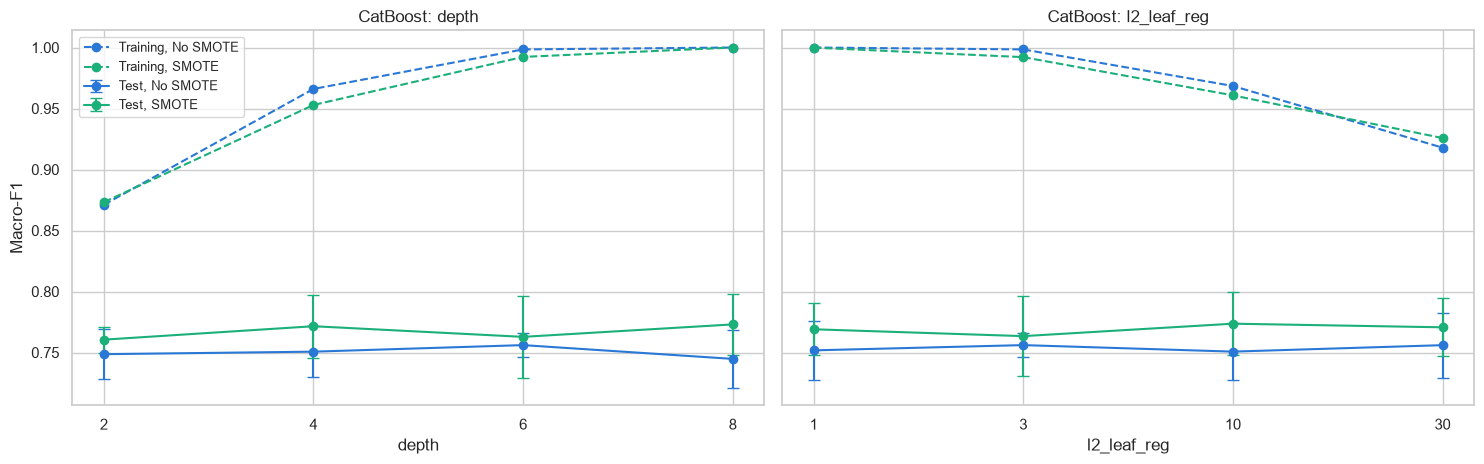

In [6]:
SWEEP_VALUES = {"depth": [2, 4, 6, 8], "l2_leaf_reg": [1, 3, 10, 30]}


def auto_learning_rate(smote):
    """Learning rate that CatBoost chooses itself for the default model (first training fold)."""
    fitted = make_cat(smote=smote).fit(X.loc[cv5[0]["train"]], y.loc[cv5[0]["train"]])
    return fitted.named_steps["model"].get_all_params()["learning_rate"]


# Setting l2_leaf_reg switches off CatBoost's automatic learning rate (it falls back to 0.03), so the
# l2_leaf_reg runs get the learning rate that CatBoost chooses for the default model
AUTO_LEARNING_RATE = {smote: auto_learning_rate(smote) for smote in (False, True)}
print("Automatic learning rate of the default model:",
      {("SMOTE" if smote else "No SMOTE"): round(rate, 4) for smote, rate in AUTO_LEARNING_RATE.items()})

sweeps = {}
for param, values in SWEEP_VALUES.items():
    for smote in (False, True):
        label = "SMOTE" if smote else "No SMOTE"
        fixed = {"learning_rate": AUTO_LEARNING_RATE[smote]} if param == "l2_leaf_reg" else {}
        sweeps[(param, label)] = pd.DataFrame(
            [{param: value, **cv_scores(make_cat(smote=smote, **fixed, **{param: value}))} for value in values]
        ).set_index(param)

for param in SWEEP_VALUES:
    print(f"{param}: 5-fold stratified CV")
    display(pd.concat(
        {label: sweeps[(param, label)][["Train Macro-F1", "Test Macro-F1", "Test Macro-F1 Std", "Gap"]]
         for label in ["No SMOTE", "SMOTE"]}, axis=1
    ).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, param in zip(axes, SWEEP_VALUES):
    for label, color in [("No SMOTE", "#2a78d6"), ("SMOTE", "#1baf7a")]:
        df = sweeps[(param, label)]
        positions = range(len(df))
        ax.plot(positions, df["Train Macro-F1"], marker="o", linestyle="--", color=color, label=f"Training, {label}")
        ax.errorbar(positions, df["Test Macro-F1"], yerr=df["Test Macro-F1 Std"], marker="o", capsize=4,
                    color=color, label=f"Test, {label}")
    ax.set_xticks(list(positions), df.index.astype(str))
    ax.set_xlabel(param)
    ax.set_title(f"CatBoost: {param}", fontsize=12)
axes[0].set_ylabel("Macro-F1")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

#### Interpretation of the manual tuning
* **`depth` without SMOTE:** the default depth 6 is the best value (0.7561, also the smallest spread, ± 0.0097). Shallower trees fit less (training 0.8711 at depth 2, 0.9660 at depth 4) without being better on the test folds (0.7486, 0.7507), and depth 8 is worse (0.7448, training 1.0).
* **`depth` with SMOTE:** depth 2 is the worst value (0.7605), as for XGBoost and LightGBM with SMOTE. Depths 4–8 are close (0.7628–0.7730), and their differences are smaller than the spread over the folds (± 0.025–0.034).
* **`l2_leaf_reg` without SMOTE** (at the automatic learning rate 0.0826): a stronger penalty lowers the training fit clearly (training macro-F1 1.0 at 1, 0.9984 at 3, 0.9685 at 10, 0.9179 at 30), and the gap shrinks from 0.2482 to 0.1619. The test macro-F1 stays between 0.7507 and 0.7561, so this reduces variance without adding bias. Even $\lambda$ = 30 (0.7560) is as good as the default.
* **`l2_leaf_reg` with SMOTE** (learning rate 0.0859): the best value is 10 (0.7736, +0.010 over 0.7634 at the default 3). 30 is also above the default (0.7707). As for XGBoost in notebook 05.1, a stronger L2 penalty helps once SMOTE has added the synthetic houses. The row with $\lambda$ = 3 differs slightly from the default model in the depth experiment (0.7634 vs. 0.7628), because with SMOTE the size of the training part, and with it the automatic learning rate, differs slightly from fold to fold.
* **Overall:** CatBoost's test score depends little on these two hyperparameters. Its trees are already strongly regularized by their structure, so additional regularization changes the training fit much more than the test score.

### 5. Bayesian optimization with Optuna (`TPESampler`)
The same procedure as in notebooks 05, 05.1 and 06 (mean macro-F1 over the same 5 stratified folds, `TPESampler` with 10 random startup trials and seed 42, `MedianPruner`), once without and once with SMOTE, stored in `optuna_ames_housing.db` (`catboost_macro_f1_tpe`, `catboost_smote_macro_f1_tpe`).

**50 trials per study instead of 100:** a CatBoost fit takes several times longer than an XGBoost or LightGBM fit (Section 3). In notebooks 05, 05.1 and 06, the best trial was found long before trial 100, so 50 trials are enough to reach the good region.

**Search space:** the CatBoost counterparts of the XGBoost hyperparameters: `depth` (3–8), `learning_rate`, the number of rounds (`iterations`, 200–1,200), the L2 penalty `l2_leaf_reg`, and CatBoost's own sources of randomness: the noise on the split scores (`random_strength`), the intensity of the Bayesian bootstrap (`bagging_temperature`, 0 = all houses weighted equally) and `rsm`, the share of features considered for each split (the counterpart of column sampling).

In [7]:
N_TRIALS = 50


def cat_params(trial):
    """One CatBoost configuration from the search space."""
    return {
        "depth": trial.suggest_int("depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "iterations": trial.suggest_int("iterations", 200, 1200, step=100),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.5, 50.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.1, 10.0, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 3.0),
        "rsm": trial.suggest_float("rsm", 0.2, 1.0),
    }


def make_objective(smote):
    def objective(trial):
        """Mean macro-F1 over the 5 stratified folds for one hyperparameter combination."""
        model = make_cat(smote=smote, **cat_params(trial))
        fold_scores = []
        for step, split in enumerate(cv5):
            fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
            pred = np.ravel(fitted.predict(X.loc[split["test"]]))
            fold_scores.append(f1_score(y.loc[split["test"]], pred, average="macro"))
            # Running mean after each fold, so the pruner can stop clearly bad trials early
            trial.report(np.mean(fold_scores), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return np.mean(fold_scores)
    return objective


def print_progress(study, trial):
    """Short status line after every 10 trials."""
    if (trial.number + 1) % 10 == 0:
        print(f"  {trial.number + 1:>3} trials: best macro-F1 {study.best_value:.4f} (trial {study.best_trial.number})")


studies = {}
for smote, study_name in [(False, "catboost_macro_f1_tpe"), (True, "catboost_smote_macro_f1_tpe")]:
    study = optuna.create_study(
        study_name=study_name, storage=STORAGE, load_if_exists=True, direction="maximize",
        sampler=TPESampler(n_startup_trials=10, seed=42), pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    )
    # Resume: only the trials that are not yet stored in the database are run
    remaining = N_TRIALS - len(study.trials)
    print(f"{study_name}: {len(study.trials)} trials stored, running {max(remaining, 0)} more")
    if remaining > 0:
        study.optimize(make_objective(smote), n_trials=remaining, callbacks=[print_progress])
    studies["SMOTE" if smote else "No SMOTE"] = study

for label, study in studies.items():
    trials = study.trials_dataframe()
    print(f"\n{label}: trial states {trials['state'].value_counts().to_dict()}, "
          f"best trial #{study.best_trial.number} with mean macro-F1 {study.best_value:.4f}")
    top = trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False).head(5)
    top = top[["number", "value"] + [col for col in trials if col.startswith("params_")]]
    display(top.rename(columns=lambda col: col.removeprefix("params_")).set_index("number").round(4))

catboost_macro_f1_tpe: 0 trials stored, running 50 more


   10 trials: best macro-F1 0.7547 (trial 7)


   20 trials: best macro-F1 0.7581 (trial 13)


   30 trials: best macro-F1 0.7581 (trial 13)


   40 trials: best macro-F1 0.7651 (trial 39)


...

   40 trials: best macro-F1 0.7797 (trial 31)


   50 trials: best macro-F1 0.7797 (trial 31)

No SMOTE: trial states {'COMPLETE': 45, 'PRUNED': 5}, best trial #48 with mean macro-F1 0.7654


,value,bagging_temperature,depth,iterations,l2_leaf_reg,learning_rate,random_strength,rsm
number,,,,,,,,
48,0.7654,2.3883,3,1100,0.6167,0.1534,2.6356,0.8960
39,0.7651,2.1134,3,1000,1.6137,0.1629,2.9459,0.8955
44,0.7602,2.1844,3,1100,1.2809,0.1201,2.0848,0.8802
13,0.7581,2.3161,4,700,5.3920,0.2576,2.4447,0.9072
47,0.7581,1.9606,4,1100,1.4034,0.1234,5.4078,0.9525



SMOTE: trial states {'COMPLETE': 49, 'PRUNED': 1}, best trial #31 with mean macro-F1 0.7797


,value,bagging_temperature,depth,iterations,l2_leaf_reg,learning_rate,random_strength,rsm
number,,,,,,,,
31,0.7797,0.3982,4,1200,1.4440,0.1017,1.9409,0.4785
22,0.7791,0.0977,5,1200,0.9429,0.0705,2.2399,0.4566
25,0.7779,0.4243,3,1200,1.6230,0.0511,2.4094,0.4800
33,0.7777,0.2446,4,1100,2.4164,0.0609,0.9593,0.4626
37,0.7771,0.2679,5,1200,0.7262,0.0437,1.8822,0.4716


#### Interpretation of the search results
* **Without SMOTE:** 45 trials finished and 5 were pruned. The best trial, #48, reaches 0.7654, above the best XGBoost (0.7556) and LightGBM (0.7568) trials on the same folds. Its hyperparameters: `depth` 3, 1,100 rounds at `learning_rate` 0.1534, `l2_leaf_reg` 0.617, `random_strength` 2.64, `bagging_temperature` 2.39 and `rsm` 0.896. The 5 best trials agree:
  * shallow trees (depth 3–4)
  * many rounds (700–1,100) at a high learning rate (0.12–0.26)
  * a small L2 penalty (0.62–5.39)
  * **more randomness than the default:** `bagging_temperature` 1.96–2.39 (a stronger Bayesian bootstrap) and `random_strength` 2.08–5.41

  CatBoost is regularized here through randomness and small trees rather than through penalties.
* **With SMOTE:** 49 trials finished and 1 was pruned. The best trial, #31, reaches 0.7797, the best value of any search in this project (XGBoost 0.7654, LightGBM 0.7690 on the same folds). Its hyperparameters: `depth` 4, 1,200 rounds at `learning_rate` 0.1017, `l2_leaf_reg` 1.44, `random_strength` 1.94, `bagging_temperature` 0.398 and `rsm` 0.479. The 5 best trials agree:
  * depth 3–5 with 1,100–1,200 rounds and a learning rate of 0.044–0.102
  * **strong feature sampling** (`rsm` 0.46–0.48) but a weak bootstrap (`bagging_temperature` 0.10–0.42)

  As for XGBoost and LightGBM, column sampling is the regularization that works with SMOTE.
* **Search limits:** with SMOTE, 4 of the 5 best trials use the maximum of 1,200 rounds, so more rounds might help a little. Without SMOTE, the best trial was only found at trial 48 of 50. Both searches are therefore probably not fully converged; the 50 trials were a compromise with the run time.

#### 5.1 Visualizations of the optimization process
For both studies: the optimization history, the hyperparameter importance (fANOVA, fixed seed) and the slice plots.

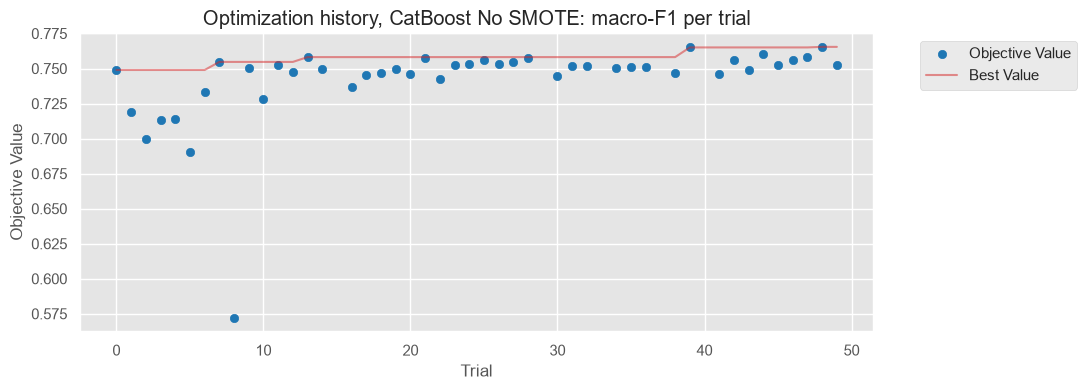

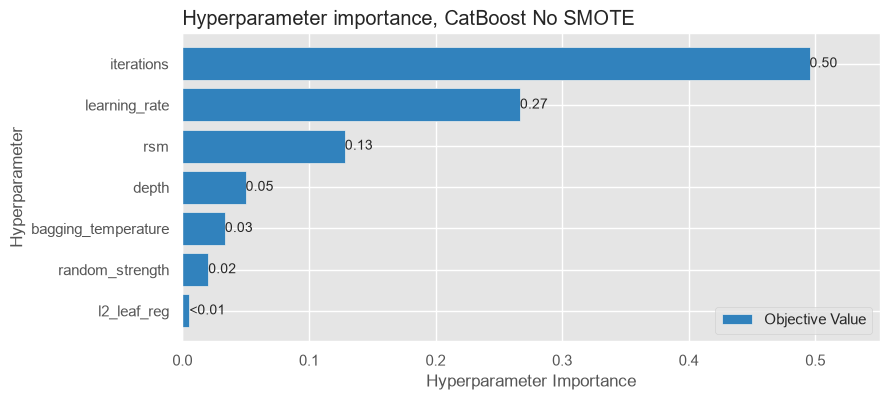

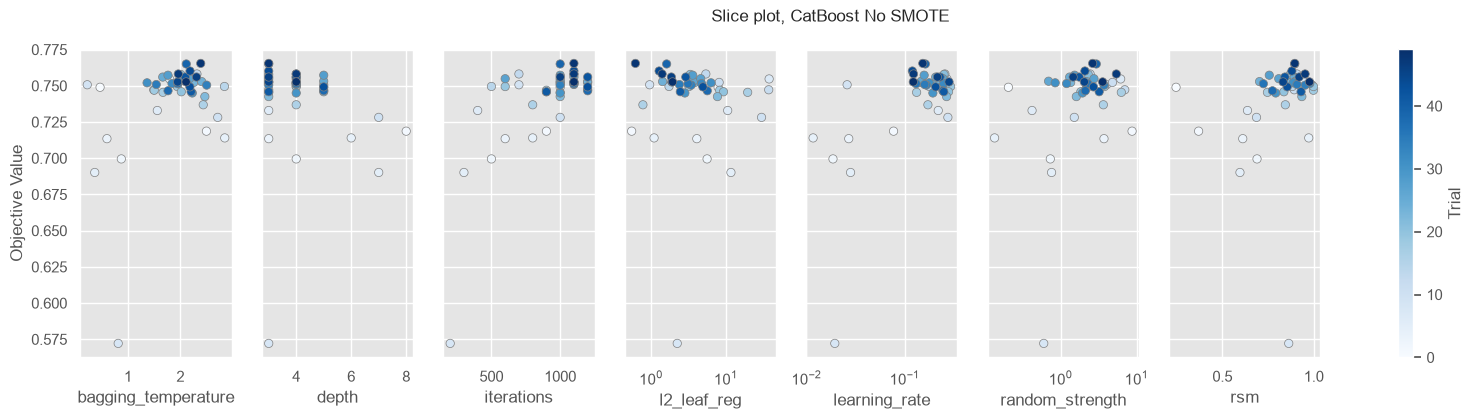

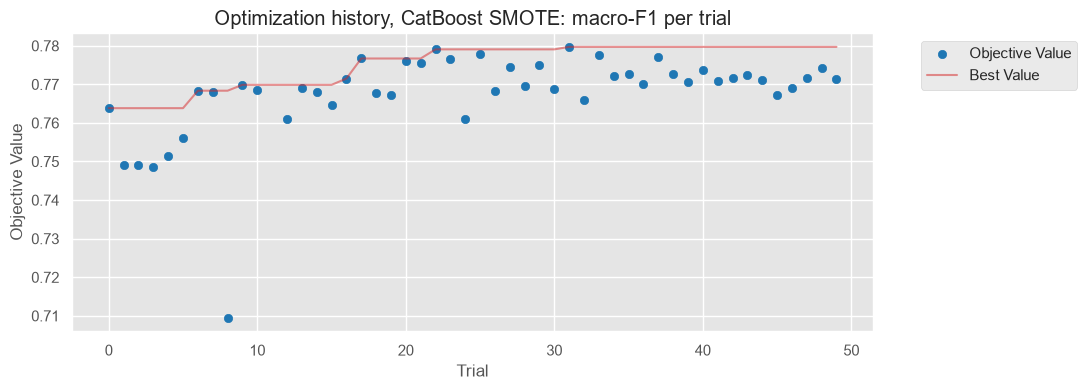

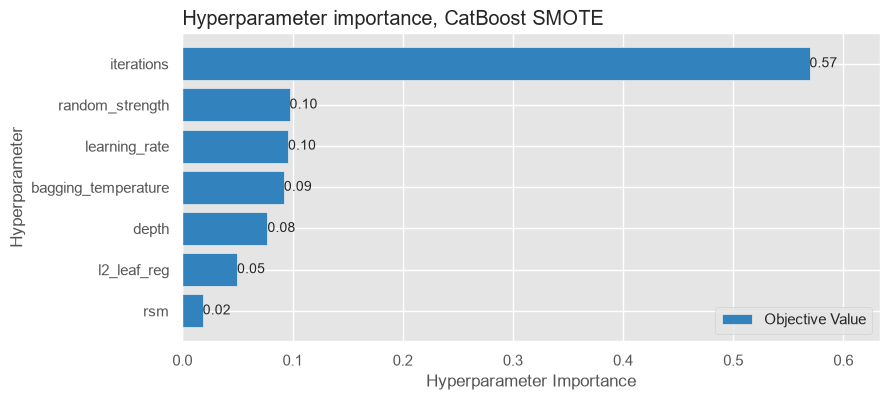

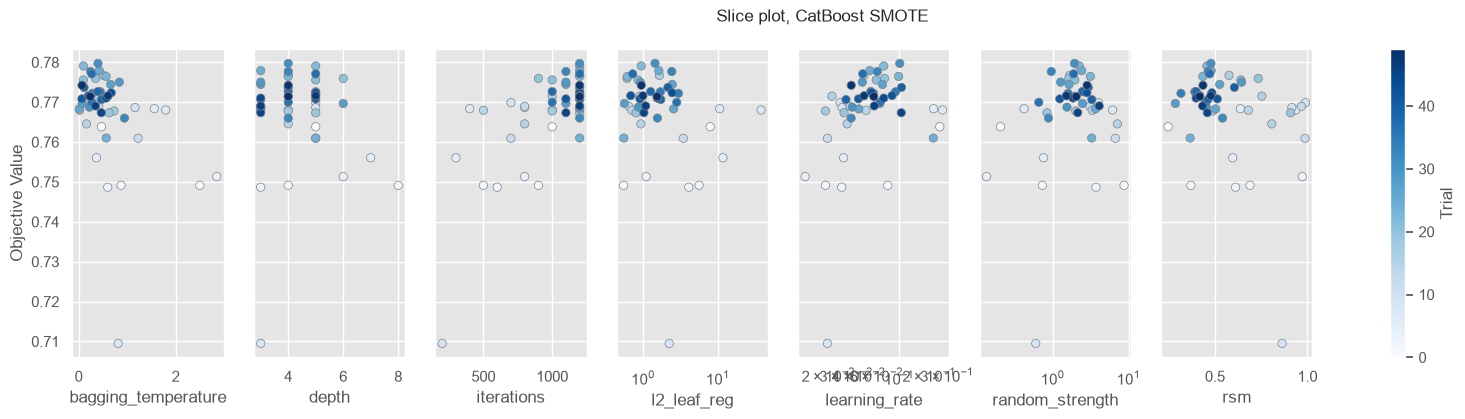

In [8]:
evaluator = optuna.importance.FanovaImportanceEvaluator(seed=42)
for label, study in studies.items():
    ax = optuna_plots.plot_optimization_history(study)
    ax.figure.set_size_inches(11, 4)
    ax.set_title(f"Optimization history, CatBoost {label}: macro-F1 per trial")
    plt.show()

    ax = optuna_plots.plot_param_importances(study, evaluator=evaluator)
    ax.figure.set_size_inches(9, 4)
    ax.set_title(f"Hyperparameter importance, CatBoost {label}", loc="left")
    plt.show()

    axes = optuna_plots.plot_slice(study)
    axes.flat[0].figure.set_size_inches(20, 4)
    axes.flat[0].figure.suptitle(f"Slice plot, CatBoost {label}")
    plt.show()

#### Interpretation of the optimization plots
* **History:** without SMOTE, the best value improves in steps until trial 48 (0.7654), with a jump at trial 39 (0.7651). With SMOTE, the search reaches 0.7767 by trial 17 and its best value at trial 31 (0.7797). The startup trials spread from about 0.57 (no SMOTE) and 0.71 (SMOTE) up to the level of the default models.
* **Importance:** unlike for XGBoost and LightGBM, the most important hyperparameters are not the penalties but the **amount of learning**. `iterations` explains 0.50 (no SMOTE) and 0.57 (SMOTE) of the variation, `learning_rate` 0.27 and 0.10. The slice plots show why: the trials with few rounds (left end of the `iterations` slice) are the worst ones. `l2_leaf_reg` hardly matters (below 0.01 without SMOTE, 0.05 with SMOTE), in line with the manual experiment. Without SMOTE, `rsm` (0.13) is third; with SMOTE, the randomness parameters (`random_strength` 0.10, `bagging_temperature` 0.09) follow.

### 6. Final comparison of the three libraries on all 70 splits
The tuned CatBoost models (best Optuna trial, without and with SMOTE) against the tuned XGBoost and LightGBM models, all fitted and scored on the same 70 splits.

In [9]:
FINAL_MODELS = {
    "XGBoost tuned (nb 05)": make_xgb(**XGB_TUNED),
    "LightGBM tuned (nb 06)": make_lgbm(**LGBM_TUNED),
    "CatBoost tuned": make_cat(**studies["No SMOTE"].best_params),
    "XGBoost SMOTE + manual (nb 05.1)": make_xgb(smote=True, **XGB_SMOTE_MANUAL),
    "LightGBM tuned + SMOTE (nb 06)": make_lgbm(smote=True, **LGBM_SMOTE_TUNED),
    "CatBoost tuned + SMOTE": make_cat(smote=True, **studies["SMOTE"].best_params),
}
final_results, final_seconds = run_models(FINAL_MODELS)

print("Test macro-F1, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Macro-F1"))
print("Test accuracy, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Accuracy"))
print("Training vs. test macro-F1 over all 70 splits, and time per fit")
display(gap_table(final_results).join(final_seconds.round(2)))
print("Paired differences in macro-F1 on the same split")
display(paired(final_results, [
    ("CatBoost tuned", "XGBoost tuned (nb 05)"),
    ("CatBoost tuned", "LightGBM tuned (nb 06)"),
    ("CatBoost tuned + SMOTE", "XGBoost SMOTE + manual (nb 05.1)"),
    ("CatBoost tuned + SMOTE", "LightGBM tuned + SMOTE (nb 06)"),
    ("CatBoost tuned + SMOTE", "CatBoost tuned"),
]))

Test macro-F1, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
XGBoost tuned (nb 05),0.7595 ± 0.0290,0.7699 ± 0.0381,0.7563 ± 0.0145,0.7656 ± 0.0198,0.7549 ± 0.0190,0.7556 ± 0.0187,0.7516 ± 0.0212,0.7502 ± 0.0481
LightGBM tuned (nb 06),0.7649 ± 0.0281,0.7652 ± 0.0516,0.7562 ± 0.0184,0.7628 ± 0.0165,0.7538 ± 0.0218,0.7568 ± 0.0284,0.7549 ± 0.0193,0.7515 ± 0.0451
CatBoost tuned,0.7744 ± 0.0170,0.7717 ± 0.0465,0.7767 ± 0.0243,0.7630 ± 0.0352,0.7635 ± 0.0185,0.7654 ± 0.0084,0.7668 ± 0.0267,0.7621 ± 0.0334
XGBoost SMOTE + manual (nb 05.1),0.7796 ± 0.0240,0.7830 ± 0.0223,0.7672 ± 0.0169,0.7779 ± 0.0185,0.7632 ± 0.0234,0.7606 ± 0.0267,0.7671 ± 0.0269,0.7703 ± 0.0387
LightGBM tuned + SMOTE (nb 06),0.7786 ± 0.0265,0.7872 ± 0.0192,0.7666 ± 0.0171,0.7719 ± 0.0238,0.7557 ± 0.0307,0.7690 ± 0.0212,0.7679 ± 0.0317,0.7677 ± 0.0379
CatBoost tuned + SMOTE,0.7812 ± 0.0237,0.7911 ± 0.0341,0.7789 ± 0.0177,0.7795 ± 0.0230,0.7676 ± 0.0233,0.7797 ± 0.0174,0.7665 ± 0.0348,0.7758 ± 0.0316


Test accuracy, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
XGBoost tuned (nb 05),0.7683 ± 0.0226,0.7799 ± 0.0260,0.7704 ± 0.0118,0.7759 ± 0.0077,0.7648 ± 0.0150,0.7768 ± 0.0202,0.7685 ± 0.0199,0.7716 ± 0.0312
LightGBM tuned (nb 06),0.7720 ± 0.0212,0.7744 ± 0.0227,0.7660 ± 0.0131,0.7750 ± 0.0112,0.7665 ± 0.0190,0.7750 ± 0.0224,0.7689 ± 0.0163,0.7713 ± 0.0275
CatBoost tuned,0.7802 ± 0.0247,0.7850 ± 0.0272,0.7814 ± 0.0155,0.7793 ± 0.0176,0.7809 ± 0.0194,0.7832 ± 0.0232,0.7873 ± 0.0245,0.7836 ± 0.0275
XGBoost SMOTE + manual (nb 05.1),0.7700 ± 0.0218,0.7788 ± 0.0209,0.7651 ± 0.0102,0.7742 ± 0.0129,0.7634 ± 0.0166,0.7634 ± 0.0238,0.7689 ± 0.0226,0.7716 ± 0.0310
LightGBM tuned + SMOTE (nb 06),0.7713 ± 0.0199,0.7826 ± 0.0192,0.7651 ± 0.0110,0.7730 ± 0.0164,0.7562 ± 0.0226,0.7740 ± 0.0259,0.7720 ± 0.0164,0.7733 ± 0.0331
CatBoost tuned + SMOTE,0.7795 ± 0.0219,0.7863 ± 0.0326,0.7744 ± 0.0171,0.7814 ± 0.0152,0.7723 ± 0.0118,0.7802 ± 0.0241,0.7726 ± 0.0211,0.7798 ± 0.0272


Training vs. test macro-F1 over all 70 splits, and time per fit


,Train Macro-F1,Test Macro-F1,Gap,Seconds per fit
Variant,,,,
XGBoost tuned (nb 05),0.9883,0.7583,0.2300,3.53
LightGBM tuned (nb 06),0.9987,0.7587,0.2401,1.55
CatBoost tuned,0.9859,0.7684,0.2175,2.75
XGBoost SMOTE + manual (nb 05.1),0.9968,0.7724,0.2244,5.68
LightGBM tuned + SMOTE (nb 06),0.9973,0.7717,0.2255,3.86
CatBoost tuned + SMOTE,0.9887,0.7781,0.2106,5.63


Paired differences in macro-F1 on the same split


CV          \
                                                   Mean Difference     Std   
CatBoost tuned − XGBoost tuned (nb 05)                      0.0121  0.0291   
CatBoost tuned − LightGBM tuned (nb 06)                     0.0106  0.0292   
CatBoost tuned + SMOTE − XGBoost SMOTE + manual...          0.0055  0.0202   
CatBoost tuned + SMOTE − LightGBM tuned + SMOTE...          0.0060  0.0203   
CatBoost tuned + SMOTE − CatBoost tuned                     0.0075  0.0246   

                                                                 \
                                                   Better Worse   
CatBoost tuned − XGBoost tuned (nb 05)               19.0  11.0   
CatBoost tuned − LightGBM tuned (nb 06)              19.0  11.0   
CatBoost tuned + SMOTE − XGBoost SMOTE + manual...   19.0  11.0   
CatBoost tuned + SMOTE − LightGBM tuned + SMOTE...   19.0  11.0   
CatBoost tuned + SMOTE − CatBoost tuned              18.0  12.0   

                                                           Holdout          \
                                                   Mean Difference     Std   
CatBoost tuned − XGBoost tuned (nb 05)                      0.0086  0.0271   
CatBoost tuned − LightGBM tuned (nb 06)                     0.0092  0.0280   
CatBoost tuned + SMOTE − XGBoost SMOTE + manual...          0.0058  0.0178   
CatBoost tuned + SMOTE − LightGBM tuned + SMOTE...          0.0066  0.0198   
CatBoost tuned + SMOTE − CatBoost tuned                     0.0112  0.0270   

                                                                 \
                                                   Better Worse   
CatBoost tuned − XGBoost tuned (nb 05)               26.0  14.0   
CatBoost tuned − LightGBM tuned (nb 06)              28.0  12.0   
CatBoost tuned + SMOTE − XGBoost SMOTE + manual...   22.0  18.0   
CatBoost tuned + SMOTE − LightGBM tuned + SMOTE...   26.0  14.0   
CatBoost tuned + SMOTE − CatBoost tuned              26.0  14.0   

                                                     All 70 splits          \
                                                   Mean Difference     Std   
CatBoost tuned − XGBoost tuned (nb 05)                      0.0101  0.0278   
CatBoost tuned − LightGBM tuned (nb 06)                     0.0098  0.0283   
CatBoost tuned + SMOTE − XGBoost SMOTE + manual...          0.0057  0.0187   
CatBoost tuned + SMOTE − LightGBM tuned + SMOTE...          0.0063  0.0199   
CatBoost tuned + SMOTE − CatBoost tuned                     0.0096  0.0259   

                                                                 
                                                   Better Worse  
CatBoost tuned − XGBoost tuned (nb 05)               45.0  25.0  
CatBoost tuned − LightGBM tuned (nb 06)              47.0  23.0  
CatBoost tuned + SMOTE − XGBoost SMOTE + manual...   41.0  29.0  
CatBoost tuned + SMOTE − LightGBM tuned + SMOTE...   45.0  25.0  
CatBoost tuned + SMOTE − CatBoost tuned              44.0  26.0

#### Interpretation of the final comparison
* **CatBoost is the best of the three libraries, with and without SMOTE:**
  * Without SMOTE, the tuned CatBoost reaches a mean test macro-F1 of 0.7684 over all 70 splits (XGBoost 0.7583, LightGBM 0.7587). It is better than XGBoost by 0.0101 (on 45 of 70 splits) and than LightGBM by 0.0098 (on 47 of 70).
  * With SMOTE, it reaches 0.7781 (XGBoost 0.7724, LightGBM 0.7717). It is better than the best XGBoost model by 0.0057 (on 41 of 70 splits) and than LightGBM by 0.0063 (on 45 of 70).
  * It has the highest mean macro-F1 in 7 of the 8 setups in both groups, and with SMOTE also the highest accuracy in all 8 setups. The gains appear on the holdout splits and on the cross-validation folds alike.
* **Less overfitting:** the CatBoost models have the smallest gaps (0.2175 and 0.2106) and do not fit the training houses perfectly (training macro-F1 0.9859 and 0.9887). The structural regularization of the symmetric trees seen in Sections 1–2 carries over to the final results.
* **SMOTE again helps:** +0.0096 for the tuned CatBoost (better on 44 of 70 splits).
* **Tuning brought speed, not accuracy:** the tuned CatBoost models score the same as the defaults of Section 3 (0.7684 vs. 0.7686 without, 0.7781 vs. 0.7780 with SMOTE), even though the tuning folds suggested a gain (0.7654 vs. 0.7561 without SMOTE). But they are much faster: 2.75 s instead of 7.47 s per fit without SMOTE, 5.63 s instead of 8.90 s with SMOTE. That puts them at the same speed as the tuned XGBoost models (3.53 / 5.68 s) and behind LightGBM (1.55 / 3.86 s).
* **How certain is it:** the differences to XGBoost and LightGBM (+0.006 to +0.010) are smaller than the standard deviation of the paired differences (0.019–0.028), and the 70 splits are not independent. But they are consistent (better on 41–47 of 70 splits, on both kinds of splits), the default CatBoost models showed the same advantage, and it fits CatBoost's smaller gap. CatBoost is very likely the better model here, by about 0.006–0.010 macro-F1.

#### 6.1 Diagnostics per class
Pooled out-of-fold predictions of the 5 stratified folds for the six tuned models: F1 and recall per class, and the confusion matrices of the three SMOTE models.

Pooled out-of-fold metrics


,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
XGBoost tuned (nb 05),0.7768,0.7885,0.7368,0.7592
LightGBM tuned (nb 06),0.7750,0.7910,0.7376,0.7608
CatBoost tuned,0.7832,0.7982,0.7450,0.7679
XGBoost SMOTE + manual (nb 05.1),0.7634,0.7667,0.7589,0.7626
LightGBM tuned + SMOTE (nb 06),0.7740,0.7744,0.7665,0.7704
CatBoost tuned + SMOTE,0.7802,0.7811,0.7797,0.7801


F1 per class


,XGBoost tuned (nb 05),LightGBM tuned (nb 06),CatBoost tuned,XGBoost SMOTE + manual (nb 05.1),LightGBM tuned + SMOTE (nb 06),CatBoost tuned + SMOTE
< 100k,0.7198,0.7330,0.7426,0.7102,0.7281,0.7368
100k–130k,0.6754,0.6815,0.7038,0.6577,0.6751,0.6834
130k–180k,0.8111,0.8131,0.8155,0.7902,0.8023,0.8044
180k–250k,0.7900,0.7813,0.7889,0.7828,0.7886,0.7941
250k–400k,0.8249,0.8036,0.8158,0.8219,0.8249,0.8365
≥ 400k,0.7339,0.7523,0.7407,0.8130,0.8033,0.8254


Recall per class


,XGBoost tuned (nb 05),LightGBM tuned (nb 06),CatBoost tuned,XGBoost SMOTE + manual (nb 05.1),LightGBM tuned + SMOTE (nb 06),CatBoost tuned + SMOTE
< 100k,0.6667,0.6835,0.6878,0.6878,0.7173,0.7089
100k–130k,0.6582,0.6601,0.6955,0.6699,0.6778,0.6955
130k–180k,0.8456,0.8485,0.8407,0.7905,0.8069,0.8079
180k–250k,0.7865,0.7836,0.7924,0.7851,0.7880,0.7836
250k–400k,0.8186,0.7884,0.8086,0.8136,0.8186,0.8438
≥ 400k,0.6452,0.6613,0.6452,0.8065,0.7903,0.8387


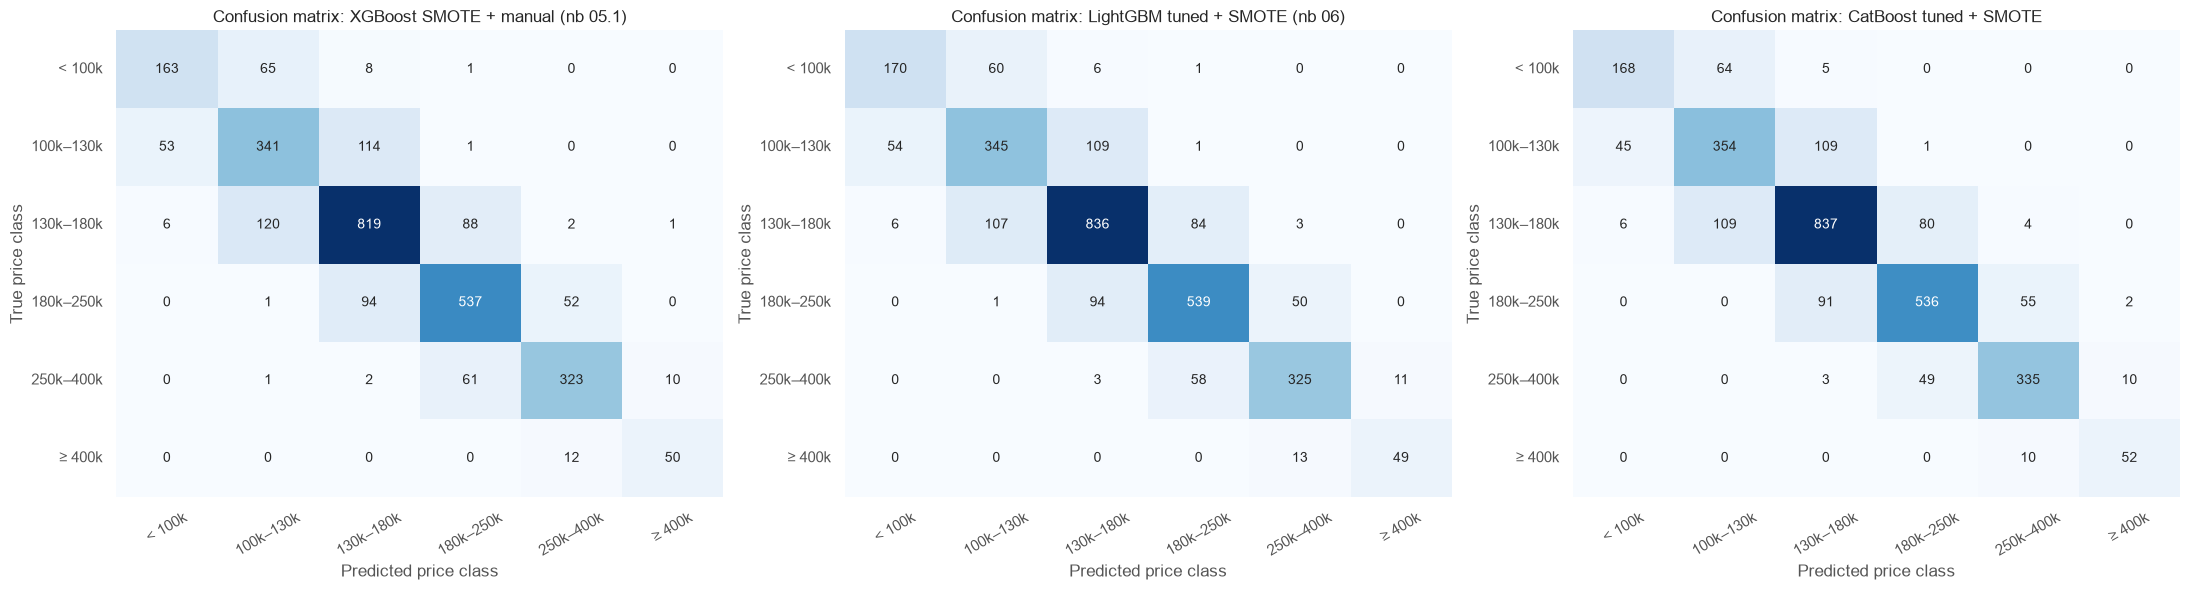

In [10]:
def out_of_fold_predictions(model):
    """Predicted class of every house from the fold in which it is a test house."""
    pred = np.zeros(len(y), dtype=int)
    for split in cv5:
        fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
        pred[y.index.get_indexer(split["test"])] = np.ravel(fitted.predict(X.loc[split["test"]]))
    return pred


y_arr = y.to_numpy()
oof_pred = {name: out_of_fold_predictions(model) for name, model in FINAL_MODELS.items()}

print("Pooled out-of-fold metrics")
display(pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_arr, pred),
        "Macro Precision": precision_score(y_arr, pred, average="macro"),
        "Macro Recall": recall_score(y_arr, pred, average="macro"),
        "Macro F1": f1_score(y_arr, pred, average="macro"),
    }
    for name, pred in oof_pred.items()
]).set_index("Model").round(4))

for metric, function in [("F1", f1_score), ("Recall", recall_score)]:
    print(f"{metric} per class")
    display(pd.DataFrame({name: function(y_arr, pred, average=None) for name, pred in oof_pred.items()},
                         index=CLASS_NAMES).round(4))

smote_models = ["XGBoost SMOTE + manual (nb 05.1)", "LightGBM tuned + SMOTE (nb 06)", "CatBoost tuned + SMOTE"]
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for ax, name in zip(axes, smote_models):
    sns.heatmap(confusion_matrix(y_arr, oof_pred[name]), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"Confusion matrix: {name}", fontsize=12)
    ax.set_xlabel("Predicted price class")
    ax.set_ylabel("True price class")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

#### Interpretation of the diagnostics
* **Pooled out-of-fold (5 stratified folds):** CatBoost with SMOTE has the highest macro-F1 (0.7801), and the two CatBoost models have the highest accuracies (0.7832 without, 0.7802 with SMOTE). Unlike the XGBoost model with SMOTE (0.7634), it loses almost no accuracy through SMOTE. As in notebooks 05.1 and 06, these are the folds the Optuna models were tuned on, so the 70 splits of Section 6 are the fairer comparison.
* **Per class with SMOTE:** CatBoost has the highest F1 of the three SMOTE models in all six classes, e.g. `< 100k` 0.7368 (XGBoost 0.7102, LightGBM 0.7281), `250k–400k` 0.8365 (0.8219, 0.8249) and `≥ 400k` 0.8254 (0.8130, 0.8033). It finds 52 of the 62 houses ≥ \$400k (XGBoost 50, LightGBM 49), and 335 of the 397 houses of `250k–400k` (323 and 325).
* **The error structure is unchanged:** in all three confusion matrices, almost all errors are in an adjacent class. The biggest weakness remains the narrow `100k–130k` class (F1 0.6834).

### Conclusion
* **How the trees are built:**
  * CatBoost grows symmetric trees, with one split condition per level for all nodes, and one tree per round for all six classes (six values per leaf).
  * With 8 leaves, a CatBoost tree has 3 split conditions on about 3 features, an XGBoost tree up to 7 conditions on about 5.5 features, and XGBoost needs six trees per round. With the default settings, CatBoost's trees use 6 different features (90% of them), XGBoost's between 1 and 30.
  * This rigid structure, together with the Bayesian bootstrap and the noise on the split scores, is a strong built-in regularization.
* **Learning process:** with the same leaf budget, CatBoost has the smallest gap between training and validation log-loss (0.1592 vs. 0.3844 for XGBoost) and the lowest validation log-loss of the three libraries. The important features are the same as for XGBoost (rank correlation 0.903), but CatBoost spreads its splits over more features. Its defaults (1,000 rounds of 64-leaf trees) are about seven times slower than XGBoost's.
* **Results:** CatBoost is the best of the three libraries.
  * Its default model already beats the tuned XGBoost and LightGBM models.
  * The tuned CatBoost reaches 0.7684 without and **0.7781 with SMOTE** (mean test macro-F1 over all 70 splits), ahead of XGBoost (0.7583 / 0.7724) and LightGBM (0.7587 / 0.7717), on most splits and in 7 of 8 setups.
  * Tuning made CatBoost faster but not better than its defaults.
* **Comparison of the three libraries:**

| | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Tree growth | depth-wise, one tree per class | leaf-wise, one tree per class | symmetric, one tree for all classes |
| Tree shape (default) | depth ≤ 6, ~19 leaves | ~31 leaves, depth up to 23 | depth 6, ~64 leaves, only 6 conditions |
| Best macro-F1 without / with SMOTE (70 splits) | 0.7583 / 0.7724 | 0.7587 / 0.7717 | **0.7684 / 0.7781** |
| Seconds per fit, tuned without / with SMOTE | 3.53 / 5.68 | 1.55 / 3.86 | 2.75 / 5.63 |

* **For the bonus ranking:** the best model of the whole analysis is CatBoost with SMOTE (tuned: 0.7781 mean test macro-F1 over the 70 splits).